# Plato Input Catalogue (PIC) 2.2.0.1 

This notebook explores the PIC 2.2.0.1 catalogue and its sub-PICs. Ultimately the goal of this work is to produce feather-format files that can used by `picsim` to generate on-demand stellar catalogues to be used by `platonium`. The output feather-format catalogues from this notebook are placed on the KU Leuven FTP located at `/STER/platoman/ftp`. From that location, `picsim` automatically downloads these files upon first execution and you can enjoy the user-friendly interface of `picsim` to generate your sub-PIC catalogues used by `PlatoSim`.

**Prerequsites** 

To run this notebook you need to download the PIC 2.1.0.1 from the [PAX](https://pax.esac.esa.int/plato/#/pages/catalog-explorer). Unzip the following two files:

- `LOPS2PICtarget2.2.0.1-t-fg-c-scv.fits`
- `LOPS2PICcontaminant2.2.0.1-t-fg-c-scv.fits`

and place them in the location: `$PLATO_PROJECT_HOME/inputfiles/data_picsim`.

**Documentation** 

The following technical notes helps you understand the PIC:

- `LOPS2PIC2.2.0.1 Release Notes (for PIC users)`
- `LOPS2PIC2.2.0.1 Data Definition Document`

**Last checked** 

This notebook was last functional with the PlatoSim version:

- `PlatoSim 3.7.0-191-g42fc64d4`

In [43]:
%load_ext autoreload
%autoreload 2
%matplotlib notebook

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [44]:
# Default packages
import os
import sys
import glob

# PlatoSim default
import h5py
import scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PLATOnium default
from pathlib import Path
from astropy.io import fits
from astropy.table import Table
from astropy.coordinates import SkyCoord
from astropy import units as u
from PyAstronomy import pyasl

# PlatoSim libraries
import platosim.plot      as pt
import platosim.utilities as ut
import platosim.pic       as pic
from platosim.simfile import SimFile
from platosim.matplotlibrc import setup_paper
setup_paper(warning=False)

from IPython.display import display, HTML
display(HTML("<style>.container {width:70% !important; }</style>"))

Relative path to catalogues (if you have placed the catalogue somewhere else on your system, simple alter the following path):

In [45]:
path = ut.getHomeDir('inputfiles/data_picsim')

---
## LOPS2 PIC 2.2.0.1 targets
---

This catalogue is the main target table, composed by the merge of four different target lists:

- `tPIC`: Core science stars (P1, P2, P4, P5) and stars with confirmed/candidate planet(s)
- `fgPIC`: Fine Guidance System (FGS) stars used to guarantee the attitude of the spacecraft
- `cPIC`: Instrument calibration stars
- `scvPIC`: Calibration and validation stars for both stellar and exoplanets science

Load target catalogue into data frame:

In [46]:
filename_targets = path / 'LOPS2PICtarget2.2.0.1-t-fg-c-scv.fits'

We will use the PIC utilities to fetch a few columns:

In [47]:
pic = pic.PIC2201(filename_targets)

For the remaining columns we fetch them manually from a data frame:

In [48]:
table = Table.read(filename_targets, format='fits')
df = table.to_pandas()
df

,PICid,PICname,StarName,RAdeg,eRAdeg,DEdeg,eDEdeg,pmRA,epmRA,pmDE,...,BOLnCameraObsNCAM_T,BOLnCameraSatNCAM_T,EOLrandomNSRNCAM_R,EOLrandomSysNSRNCAM_R,EOLnCameraObsNCAM_R,EOLnCameraSatNCAM_R,tPICscientificRanking,scvPICscientificRanking,scientificPriority,scheduledTarget
0,3098133000271,b'PIC 3098133000271',b'Gaia DR3 4648564604791874688',84.548965,0.159458,-75.874403,0.180793,-3.102064,0.012864,12.663421,...,0,0,133.600006,133.899994,0,0,0.004622,<NA>,<NA>,<NA>
1,3098130000327,b'PIC 3098130000327',b'Gaia DR3 4648246433616908160',82.636521,0.126920,-75.871390,0.139425,20.555716,0.010246,40.802000,...,0,0,152.399994,152.699997,0,0,0.015314,<NA>,<NA>,<NA>
2,3098125000342,b'PIC 3098125000342',b'Gaia DR3 4648987573177352576',79.661507,0.174732,-75.867457,0.157135,-4.791629,0.013962,9.420978,...,0,0,281.799988,282.000000,0,0,0.000974,<NA>,<NA>,<NA>
3,3098136000261,b'PIC 3098136000261',b'Gaia DR3 4648377790895956096',86.259963,0.163587,-75.861752,0.200761,-1.406063,0.013268,22.950370,...,0,0,152.399994,152.699997,0,0,0.000776,<NA>,<NA>,<NA>
4,3098125000383,b'PIC 3098125000383',b'Gaia DR3 4648987465797348480',79.572931,0.187630,-75.858905,0.174225,7.379638,0.014900,-5.899641,...,0,0,279.700012,279.799988,0,0,0.001540,<NA>,<NA>,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
289248,2584245001092,b'PIC 2584245001092',b'Gaia DR3 5534611474577640576',121.700934,0.170716,-39.982180,0.197368,-0.605033,0.013830,7.863984,...,12,0,235.899994,236.000000,11,0,NaN,1,<NA>,<NA>
289249,2375324001251,b'PIC 2375324001251',b'Gaia DR3 5598585532155150208',117.339771,0.171734,-30.635653,0.199072,-5.730499,0.013927,9.028191,...,6,0,372.100006,372.299988,6,0,NaN,1,<NA>,<NA>
289250,2947056000215,b'PIC 2947056000215',b'Gaia DR3 5289461200952847616',116.497274,0.188520,-60.880089,0.196478,-0.596529,0.015310,3.962600,...,6,0,322.200012,322.299988,6,0,NaN,1,<NA>,<NA>
289251,2639419000234,b'PIC 2639419000234',b'Gaia DR3 5526512922907328896',127.855655,0.142809,-42.742764,0.148042,-2.010023,0.011747,2.125126,...,6,0,431.200012,431.299988,5,0,NaN,1,<NA>,<NA>


Check the column names:

In [49]:
df.columns

Index(['PICid', 'PICname', 'StarName', 'RAdeg', 'eRAdeg', 'DEdeg', 'eDEdeg',
       'pmRA', 'epmRA', 'pmDE', 'epmDE', 'pm', 'epm', 'Plx', 'ePlx',
       'distance', 'edistance', 'Glon', 'Glat', 'posEpoch', 'refEpoch',
       'posPropFlag', 'PlatoMagNCAM', 'ePlatoMagNCAM', 'PlatoMagFCAMb',
       'ePlatoMagFCAMb', 'PlatoMagFCAMr', 'ePlatoMagFCAMr', 'Gmag', 'eGmag',
       'BPmag', 'eBPmag', 'RPmag', 'eRPmag', 'Hpmag', 'eHpmag', 'Ksmag',
       'eKsmag', 'AG', 'eAG', 'AKs', 'eAKs', 'EBPRP', 'eEBPRP', 'extStatus',
       'VmagCalculated', 'eVmagCalculated', 'Teff', 'eTeff', 'Radius',
       'eRadius', 'Mass', 'eMass', 'caseFlag', 'PICmainSourceFlagBOL',
       'tPICsourceFlagNCAM_BOL', 'fgPICsourceFlag', 'cPICsourceFlag',
       'scvPICsourceFlag', 'NSSFlag', 'qualityFlag', 'tPICplanetFlag',
       'fgPICcPICvariabilityFlag', 'targetStatusFlag', 'BOLrandomNSRNCAM_T',
       'BOLrandomSysNSRNCAM_T', 'BOLnCameraObsNCAM_T', 'BOLnCameraSatNCAM_T',
       'EOLrandomNSRNCAM_R', 'EOLrandomSysNSR

Define a new dataframe and copy over the columns we need:

In [50]:
# Add Galactic coordinates
gal = SkyCoord(df.RAdeg, df.DEdeg, frame='icrs', unit=u.deg).galactic
# Create data frame
dt = pd.DataFrame()
dt['PIC']     = df.PICid
dt['gaiaDR3'] = df.StarName
dt['l']       = gal.l.deg
dt['b']       = gal.b.deg
dt['ra']      = df.RAdeg
dt['dec']     = df.DEdeg
dt['pmra']    = df.pmRA
dt['pmdec']   = df.pmDE
dt['plx']     = df.Plx
dt['Pmag']    = df.PlatoMagNCAM
dt['PBmag']   = df.PlatoMagFCAMb
dt['PRmag']   = df.PlatoMagFCAMr
dt['Vmag']    = df.VmagCalculated
dt['M']       = df.Mass
dt['M_err']   = df.eMass
dt['R']       = df.Radius
dt['R_err']   = df.eRadius
dt['Teff']    = df.Teff
dt['Teff_err']= df.eTeff
dt['logg']    = pic.get_logg()
dt['ncams']   = df.BOLnCameraObsNCAM_T
dt['case']    = df.caseFlag
dt['source']  = df.PICmainSourceFlagBOL
dt['tPIC']    = df.tPICsourceFlagNCAM_BOL
dt['fgPIC']   = df.fgPICsourceFlag
dt['cPIC']    = df.cPICsourceFlag
dt['scvPIC']  = df.scvPICsourceFlag
dt.ncams.unique()

<IntegerArray>
[0, 6, 12, 18, 24, <NA>]
Length: 6, dtype: Int16

Remove stars ouside of visibility flower:

In [51]:
dt0 = dt[dt.ncams != 0]
dt0 = dt0.reset_index(drop=True)

Save `picsim` target catalogue:

In [ ]:
dt0.to_feather(path / 'PIC220_LOPS2_targets.ftr')
dt0

Add F-CAM flag to select stars landing on silicon for the F-CAMs

In [81]:
# To run this section one needs further downloading 
# (instructions will come soon..)
# # Load F-CAM blue
# odir = ut.getWorkDir('plato_scvPIC') / 'output'
# cam = 2
# # Load full-frame images
# f1 = h5py.File(odir / f'Fcam{cam}_Q1_ccd1.hdf5', "r")
# f2 = h5py.File(odir / f'Fcam{cam}_Q1_ccd2.hdf5', "r")
# f3 = h5py.File(odir / f'Fcam{cam}_Q1_ccd3.hdf5', "r")
# f4 = h5py.File(odir / f'Fcam{cam}_Q1_ccd4.hdf5', "r")
# im1 = np.array(f1['Images']['image0000000'])
# im2 = np.array(f2['Images']['image0000000'])
# im3 = np.array(f3['Images']['image0000000'])
# im4 = np.array(f4['Images']['image0000000'])
# # Load F-CAM stars on silicon
# df1 = pd.read_feather(odir / f'Fcam{cam}_Q1_ccd1.ftr')
# df2 = pd.read_feather(odir / f'Fcam{cam}_Q1_ccd2.ftr')
# df3 = pd.read_feather(odir / f'Fcam{cam}_Q1_ccd3.ftr')
# df4 = pd.read_feather(odir / f'Fcam{cam}_Q1_ccd4.ftr')
# df = pd.concat([df1, df2, df3, df4]).drop_duplicates(subset='PIC').reset_index(drop=True)
# # Cross-match with tPIC
# dt1 = dt[dt['PIC'].isin(df['PIC'])].sort_values(by=['Pmag']).reset_index(drop=True)
# # Check with plot
# dx = dt1.copy()
# fig, ax = pt.plotPlatoFOV(
#     'LOPS2', system='galactic', fovSize=19, ncamStars=dx,
#     figsize=(10,10), title=f'{dx.shape[0]} PIC targets'
# )

---
## LOPS2 PIC 2.2.0.1 contaminants
---

Open fits file and inspect it:

In [11]:
filename = path / 'LOPS2PICcontaminant2.2.0.1-t-fg-c-scv.fits'
hdul = fits.open(filename, memmap=True)

Note that this catalogue contains 105,865,176 sources:

In [12]:
hdul.info()

Filename: /lhome/nicholas/software/PlatoSim3/inputfiles/data_picsim/LOPS2PICcontaminant2.2.0.1-t-fg-c-scv.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1                1 BinTableHDU    217   105865176R x 43C   [K, 17A, 28A, D, D, D, D, D, E, D, E, D, D, D, E, E, E, E, E, I, D, D, D, D, D, D, I, D, D, D, D, D, D, E, E, E, E, E, E, I, I, I, I]   


Check tabel column names

In [13]:
hdul[1].header

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / 8-bit bytes                                    
NAXIS   =                    2 / 2-dimensional table                            
NAXIS1  =                  285 / width of table in bytes                        
NAXIS2  =            105865176 / number of rows in table                        
PCOUNT  =                    0 / size of special data area                      
GCOUNT  =                    1 / one data group                                 
TFIELDS =                   43 / number of columns                              
TTYPE1  = 'PICcontaminantId'   / label for column 1                             
TFORM1  = 'K       '           / format for column 1                            
TCOMM1  = 'Unique PIC contaminant identifier'                                   
TUCD1   = 'meta.id;meta.main'                                                   
TTYPE2  = 'PICcontaminantNam

Workaround to load huge data table into a data frame:

In [14]:
dc = pd.DataFrame()
campos = {
    'PIC'     : 'PICcontaminantId',
    'gaiaDR3' : 'StarName',
    'ra'      : 'RAdeg', 
    'dec'     : 'DEdeg',
    'Gmag'    : 'Gmag',
    'Pmag'    : 'PlatoMagNCAM',
    'PBmag'   : 'PlatoMagFCAMb',
    'PRmag'   : 'PlatoMagFCAMr'
}
print('FECTHING COLUMNS FROM CONTAMINANT TABLE:')
print('-'*40)
for campo_dc, campo_pic in campos.items():
    # Print each column to follow progress
    print(campo_pic)
    col = hdul[1].data[campo_pic]
    # Fetch magnitude column and get bool indices for P < 19
    if campo_dc == 'Pmag':
        dx = pd.DataFrame({'Pmag': col})
        dex = dx.Pmag < 19
    # Fetch each column
    dc[campo_dc] = col.byteswap().view(col.dtype.newbyteorder())
print('-'*40)

FECTHING COLUMNS FROM CONTAMINANT TABLE:
----------------------------------------
PICcontaminantId
StarName
RAdeg
DEdeg
Gmag
PlatoMagNCAM
PlatoMagFCAMb
PlatoMagFCAMr
----------------------------------------


In [24]:
dc['gaiaDR3'] = pic.get_GaiaDR3_ID(dc, column='gaiaDR3')
dc.head()

,PIC,gaiaDR3,ra,dec,Gmag,Pmag,PBmag,PRmag
0,3110756000112,5212190448627272832,95.193683,-77.886883,15.213778,14.926610,15.235669,14.596222
1,3110756000113,5212190616130246656,95.141286,-77.886858,18.240141,17.982211,18.237360,17.696458
2,3110756000114,5212190482985986944,95.298362,-77.886773,20.510187,20.196406,20.565547,19.821192
3,3110757000129,5212236623819501440,95.888141,-77.886079,20.385687,20.068541,20.446212,19.687329
4,3110757000130,5212236795618194176,95.809169,-77.885670,19.580097,19.334407,19.569914,19.066083


Show the number of sources for different magnitude limits:

In [25]:
dc19 = dc.loc[dex].reset_index(drop=True)
dc19.shape[0]/1e6

45.116663

In [26]:
dc17 = dc[dc.Pmag < 17].reset_index(drop=True)
dc17.shape[0]/1e6

13.125668

In [27]:
dc15 = dc17[dc17.Pmag < 15].reset_index(drop=True)
dc15.shape[0]/1e6

3.385929

In [30]:
path

PosixPath('/lhome/nicholas/software/PlatoSim3/inputfiles/data_picsim')

Save contaminant catalogue to cross-match with for GO proposals

In [91]:
dc19.to_feather(path / 'PlatoGO_PIC220_LOPS2.ftr')

We make a cut to keep the catalogue managable and remove NaNs:

In [28]:
dc17 = dc17.dropna(subset=['PIC', 'ra', 'dec', 'Pmag', 'PBmag', 'PRmag'])
# dc17.pmra = dc17.pmra.replace(np.nan, 0)
# dc17.pmdec = dc17.pmdec.replace(np.nan, 0)

Since the PIC 2.2.0.1 contaminant table do not include unique PIC identifiers related to each target star we need to generate this ourselves:

In [100]:
dc_cut = ut.getContaminants(dt, dc17, column='PIC', radius=60)

100%|██████████████████████████████████████████████████| 289253/289253 [5:33:59<00:00, 14.43it/s]    


In [101]:
dc_cut = dc_cut.reset_index(drop=True)
dc_cut

,PIC,gaiaDR3,ra,dec,Gmag,Pmag,PBmag,PRmag,dis
0,3.098133e+12,Gaia DR3 4648564604797660288,84.561690,-75.885606,12.983585,12.720928,12.983360,12.428690,41.848512
1,3.098136e+12,Gaia DR3 4648377790895955456,86.248821,-75.862302,15.534974,15.256943,15.547705,14.941191,9.995941
2,3.098125e+12,Gaia DR3 4648987470098135424,79.566889,-75.860163,16.274323,15.987543,16.295728,15.657919,6.980812
3,3.098125e+12,Gaia DR3 4648987848055256576,79.559094,-75.845687,17.009531,16.637445,17.164195,16.167209,49.118412
4,3.097516e+12,Gaia DR3 4648381329948992384,85.845627,-75.858153,13.934879,13.483351,14.786755,12.737154,1.003920
...,...,...,...,...,...,...,...,...,...
1403411,2.935596e+12,Gaia DR3 5302121806772404480,129.894228,-60.008217,16.864481,16.572015,16.892075,16.233054,36.894540
1403412,2.935596e+12,Gaia DR3 5302122042991148160,129.895012,-59.992659,15.299934,15.055106,15.289189,14.788033,42.666597
1403413,2.935596e+12,Gaia DR3 5302122047290574848,129.894765,-59.992582,17.298901,16.847372,18.150776,16.101175,43.164681
1403414,2.935596e+12,Gaia DR3 5302497152555006464,129.917282,-59.987334,11.314436,10.953342,11.439109,10.505485,53.531699


Save `picsim` contaminant catalogue:

In [102]:
dc_cut.to_feather(path / 'PIC220_LOPS2_contaminants.ftr')

---
## Plot the PIC target catalogue (within footprint)
---

All PIC targets:

<IPython.core.display.Javascript object>


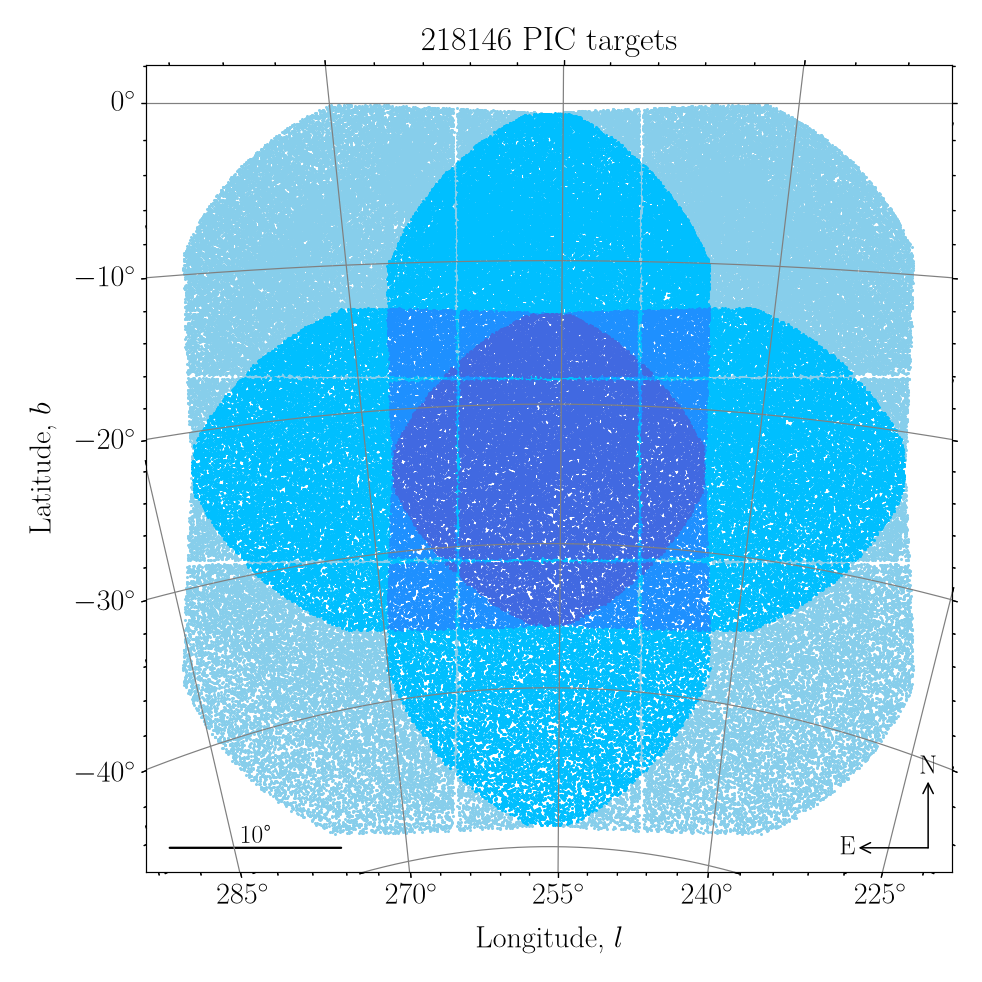

In [10]:
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    figsize=(9,9), title=f'{dt0.shape[0]} PIC targets'
)

---
### Plots for tPIC

Plot `tPIC` targets:

<IPython.core.display.Javascript object>


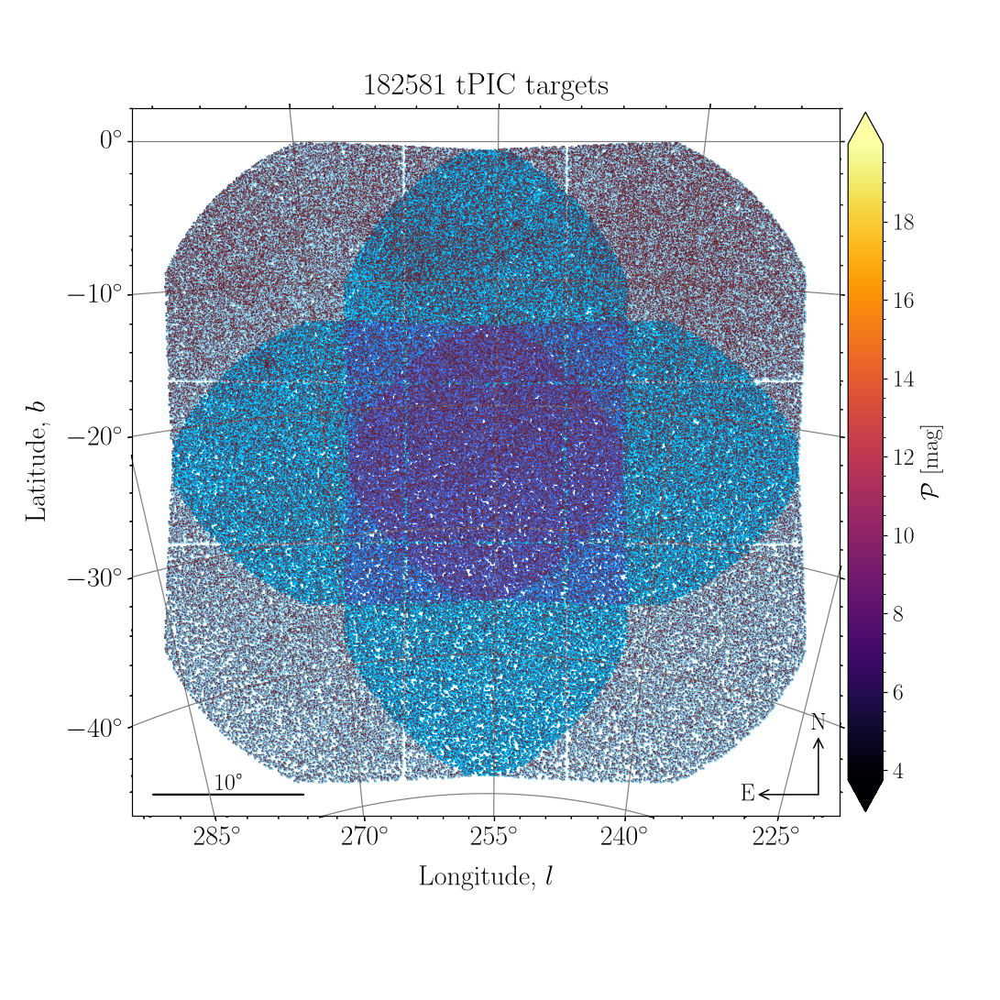

In [227]:
dx = dt[(dt['source'] & 4 == 4) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} tPIC targets'
)

Plot all `Prime` sample targets:

<IPython.core.display.Javascript object>


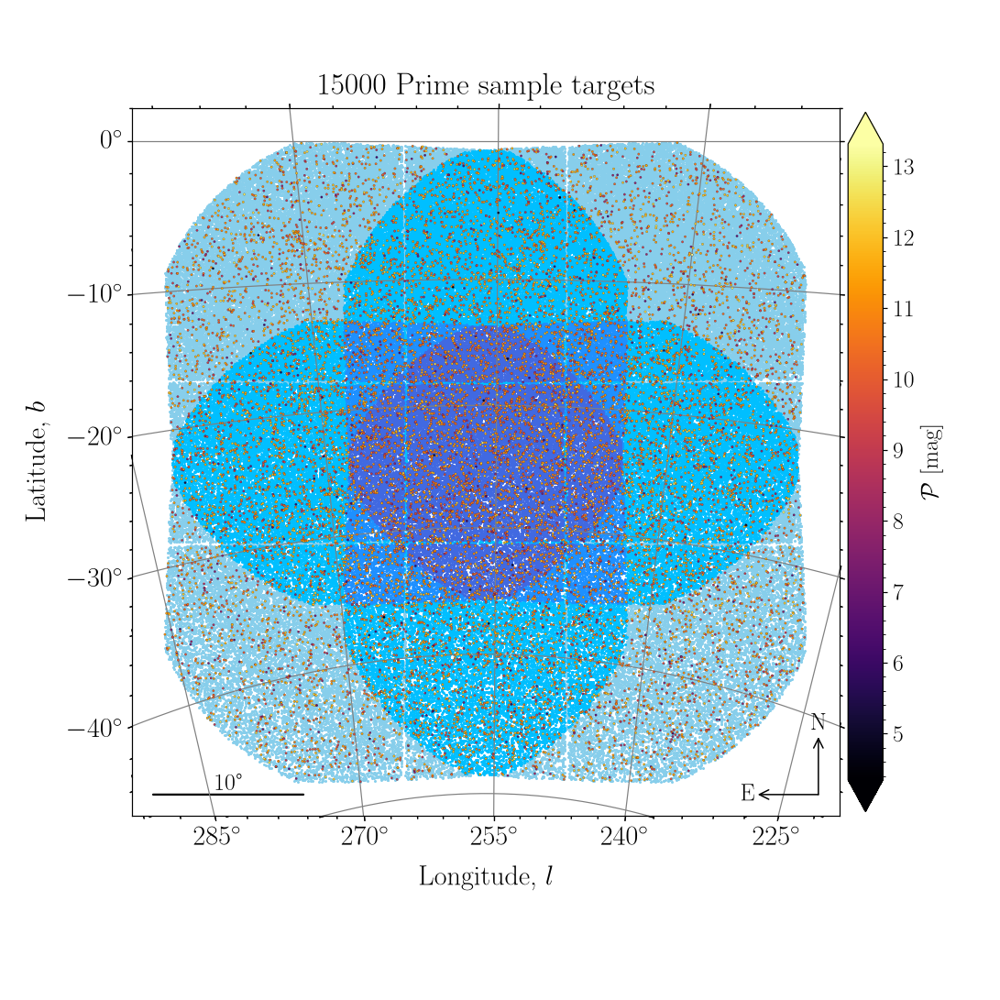

In [27]:
dx = dt[(dt.tPIC & 32 == 32) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} Prime sample targets'
)
# Sanity check for Teff and B-V
# np.count_nonzero(np.isnan(dx.B_V))

Plot all `P1` targets and their planets (candidates):

<IPython.core.display.Javascript object>


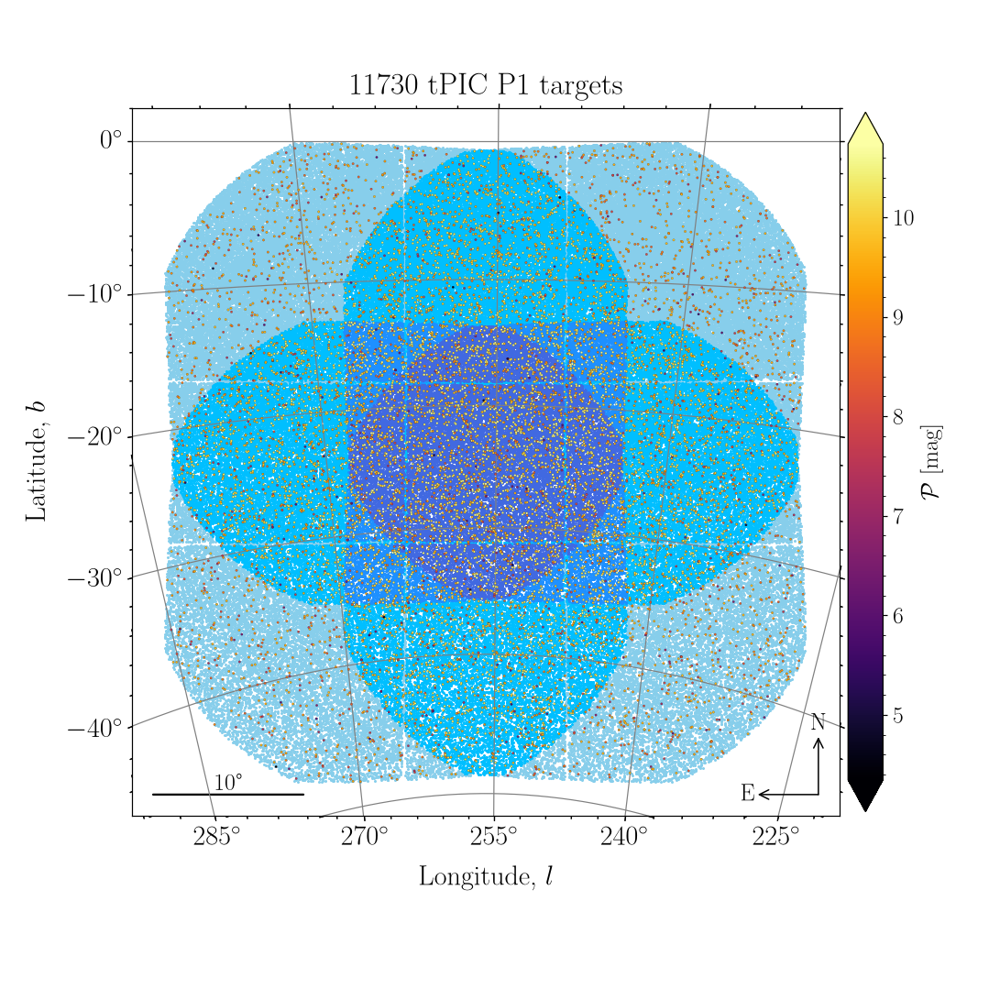

In [277]:
dx = dt[(dt.tPIC & 1 == 1) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P1 targets'
)

<IPython.core.display.Javascript object>


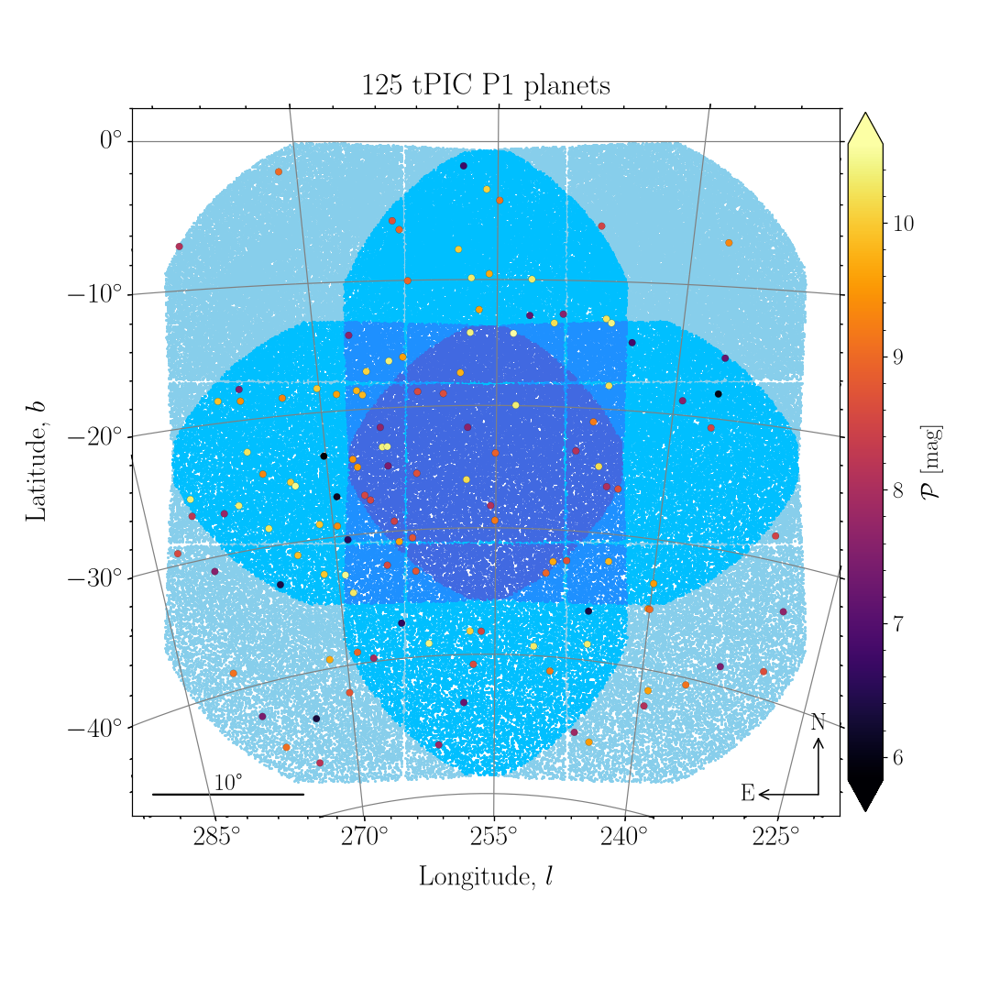

In [229]:
dx = dt[(dt.tPIC & 1 == 1) & (dt.tPIC & 16 == 16) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P1 planets'
)

Plot all `P2` targets and their planets (candidates):

<IPython.core.display.Javascript object>


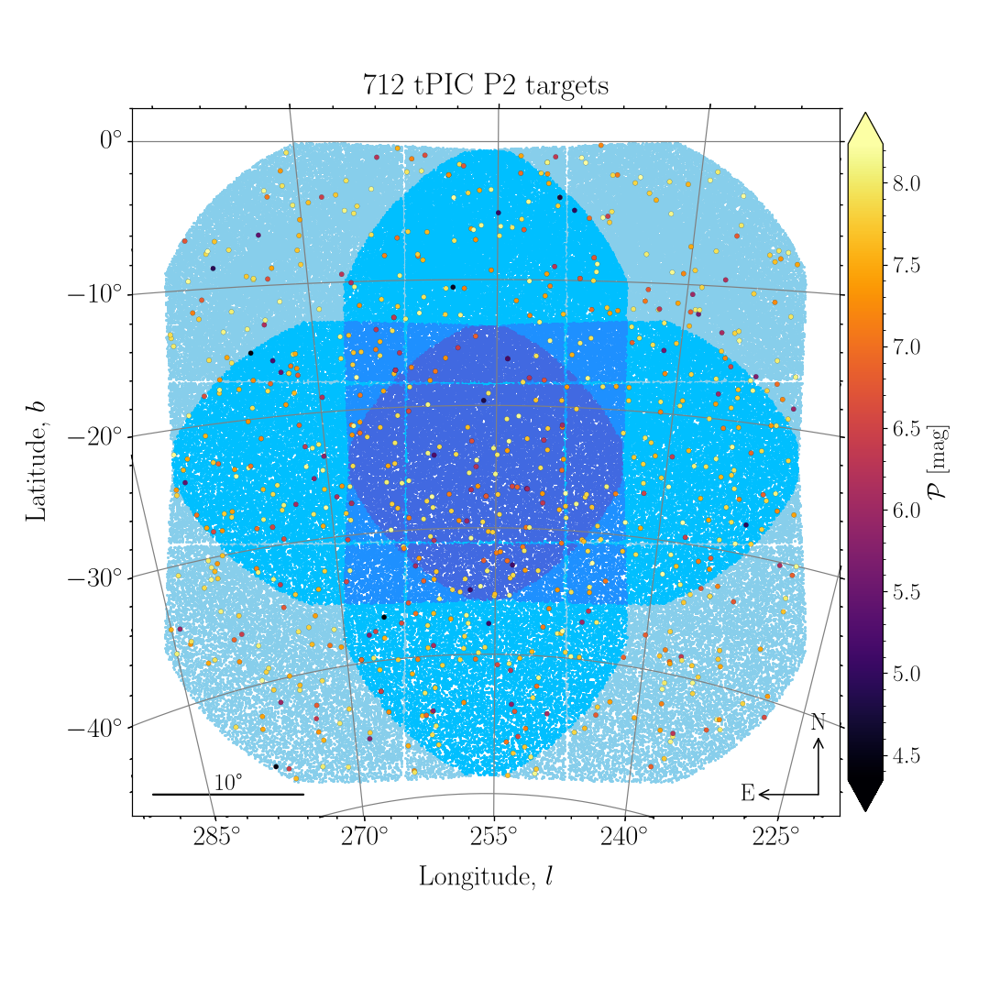

In [230]:
dx = dt[(dt.tPIC & 2 == 2) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P2 targets'
)

<IPython.core.display.Javascript object>


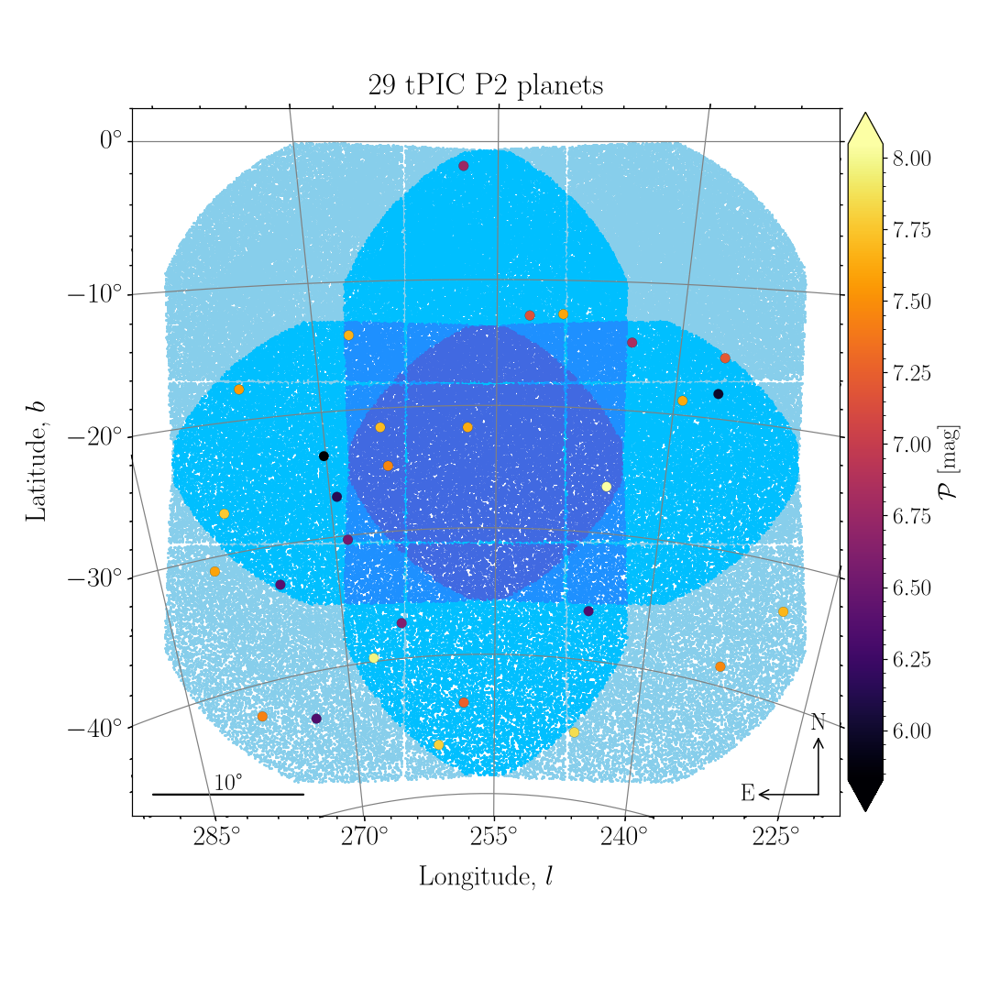

In [231]:
dx = dt[(dt.tPIC & 2 == 2) & (dt.tPIC & 16 == 16) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P2 planets'
)

Plot all `P4` targets and their planets (candidates):

<IPython.core.display.Javascript object>


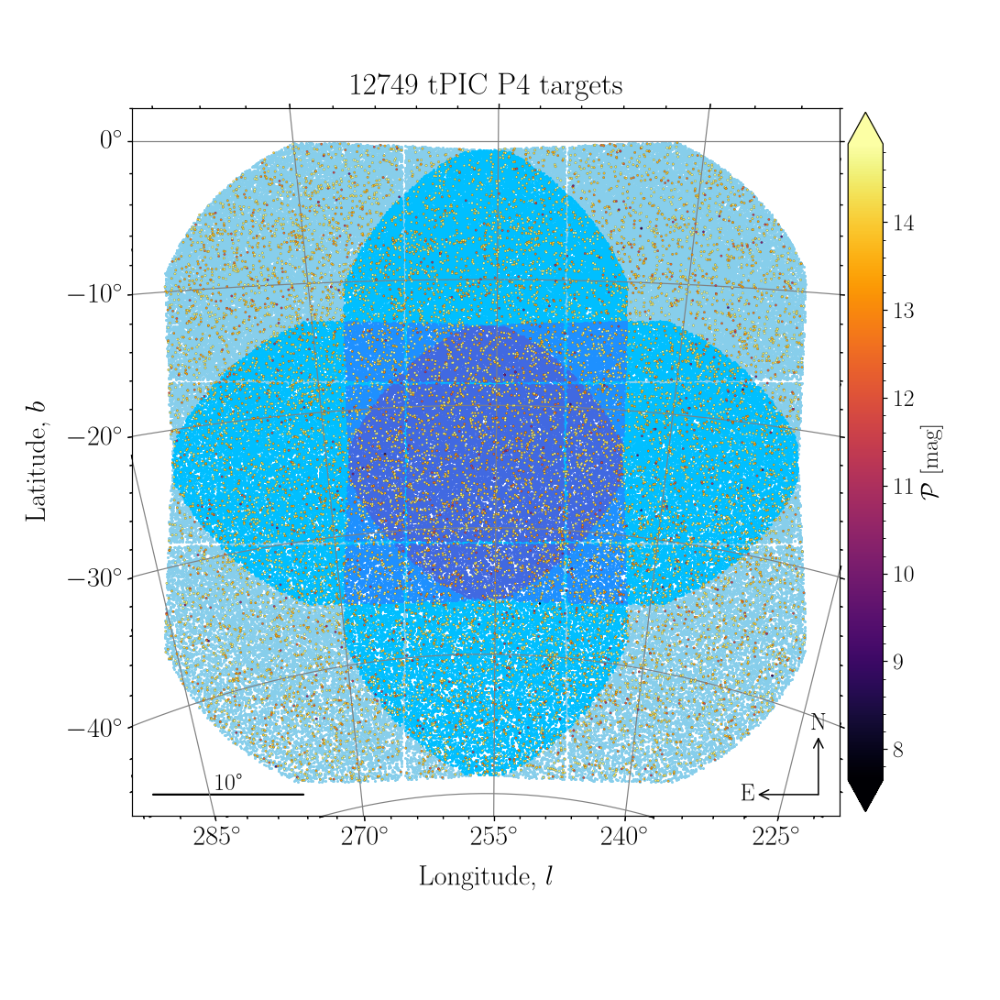

In [232]:
dx = dt[(dt.tPIC & 8 == 8) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P4 targets'
)

<IPython.core.display.Javascript object>


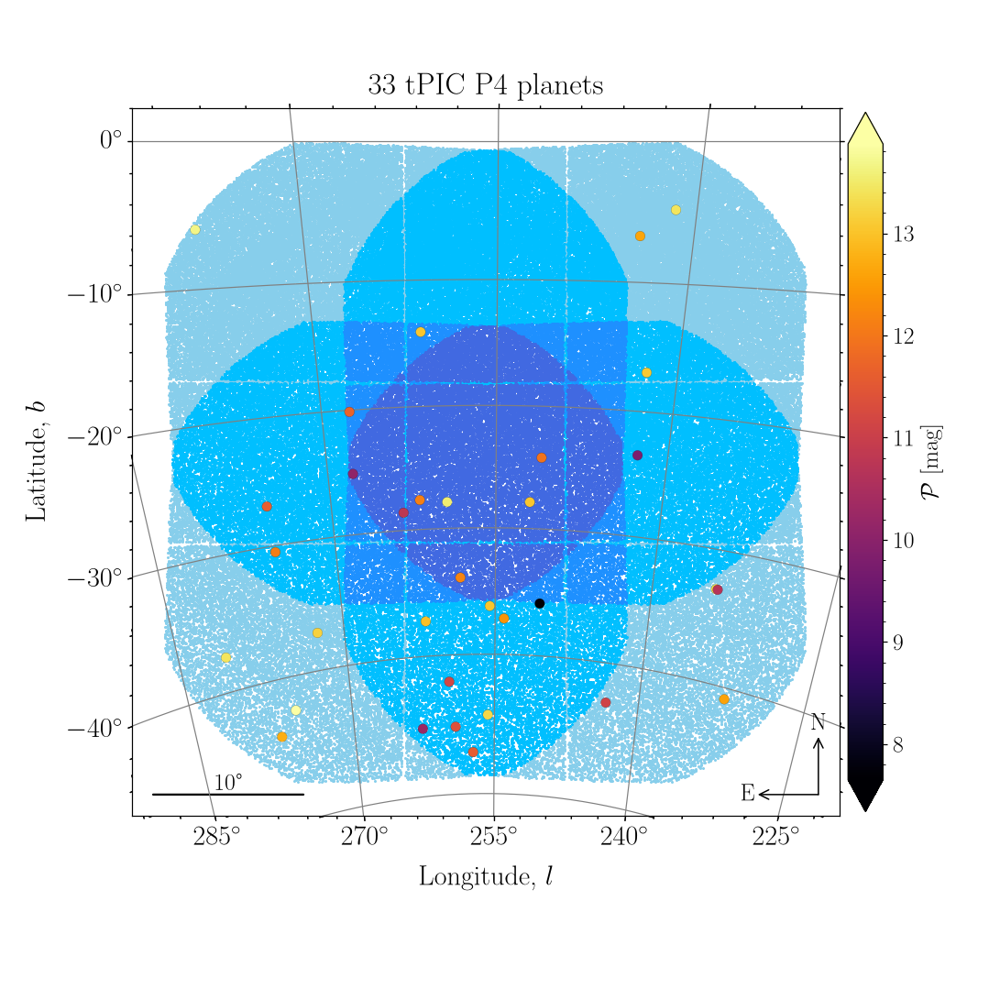

In [233]:
dx = dt[(dt.tPIC & 8 == 8) & (dt.tPIC & 16 == 16) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P4 planets'
)

Plot all `P5` targets and their planets (candidates):

<IPython.core.display.Javascript object>


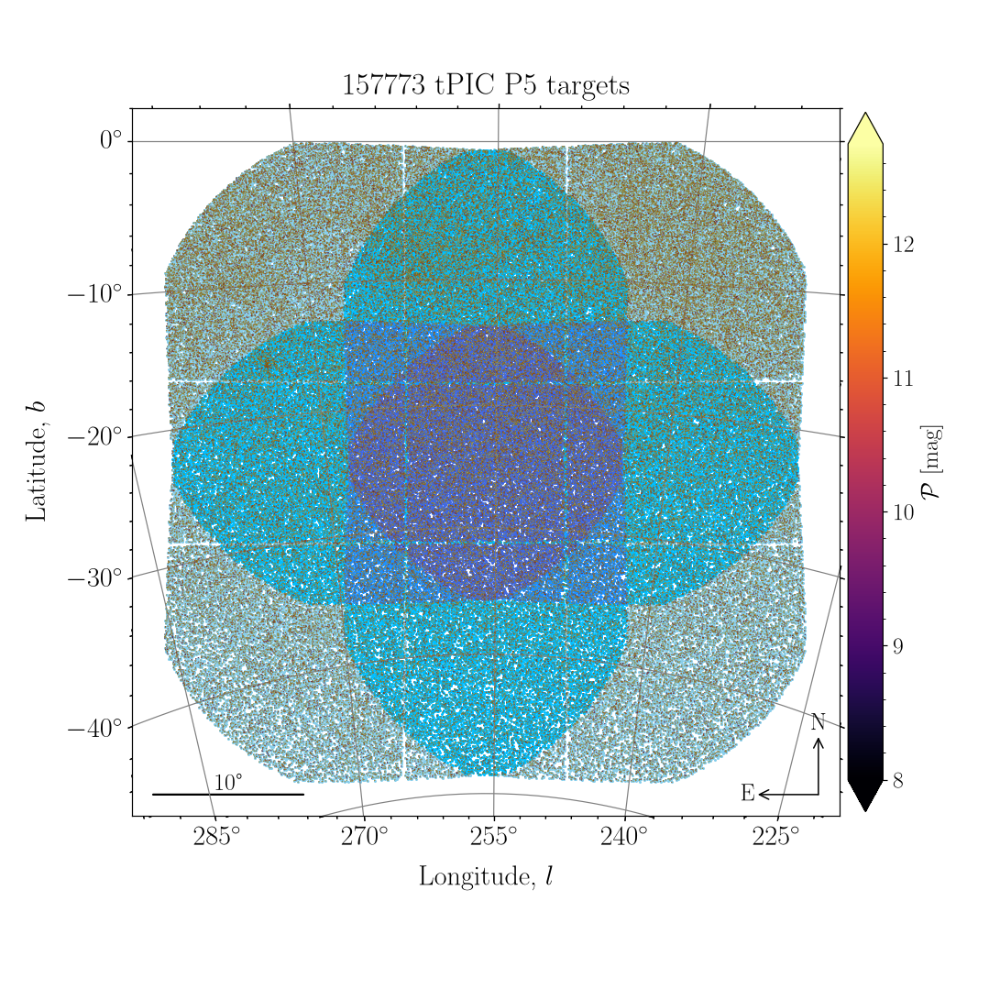

In [234]:
dx = dt[(dt.tPIC & 4 == 4) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P5 targets'
)

<IPython.core.display.Javascript object>


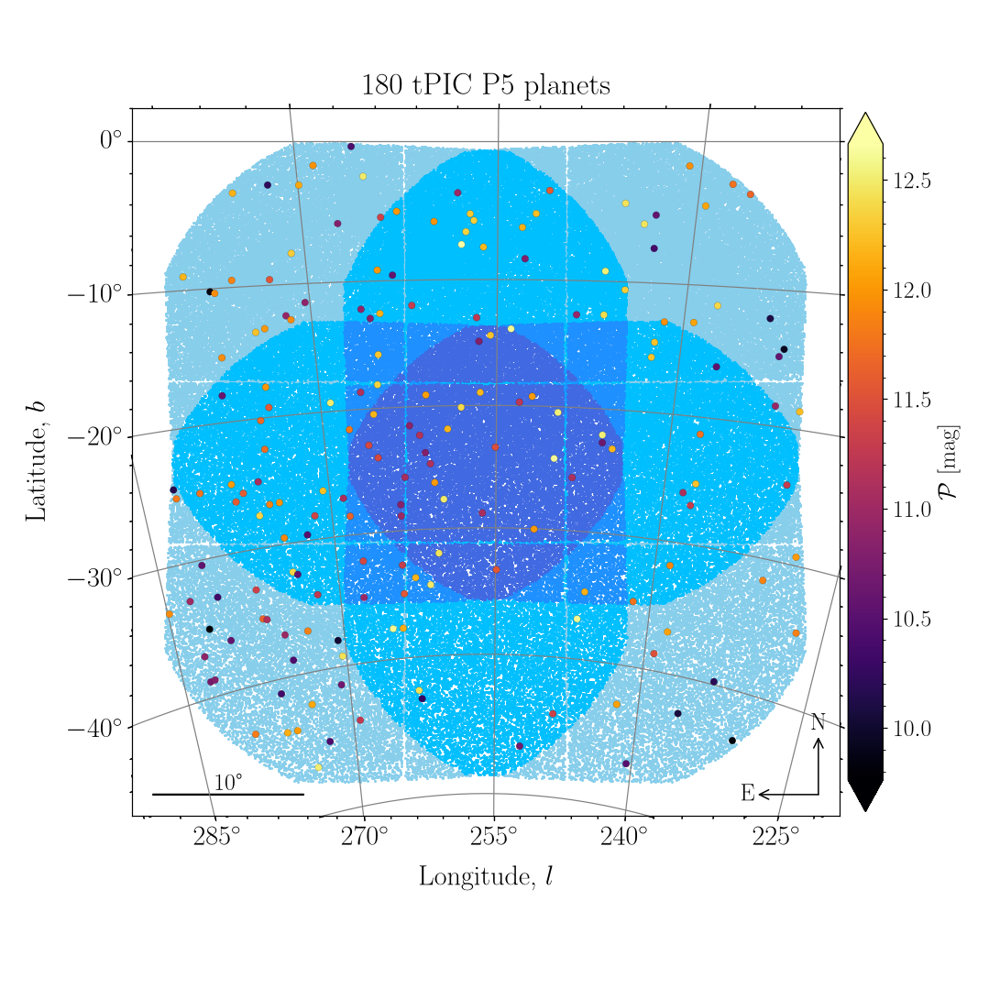

In [235]:
dx = dt[(dt.tPIC & 4 == 4) & (dt.tPIC & 16 == 16) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P5 planets'
)

---
### Plots for fgPIC

Plot `fgPIC` targets:

<IPython.core.display.Javascript object>


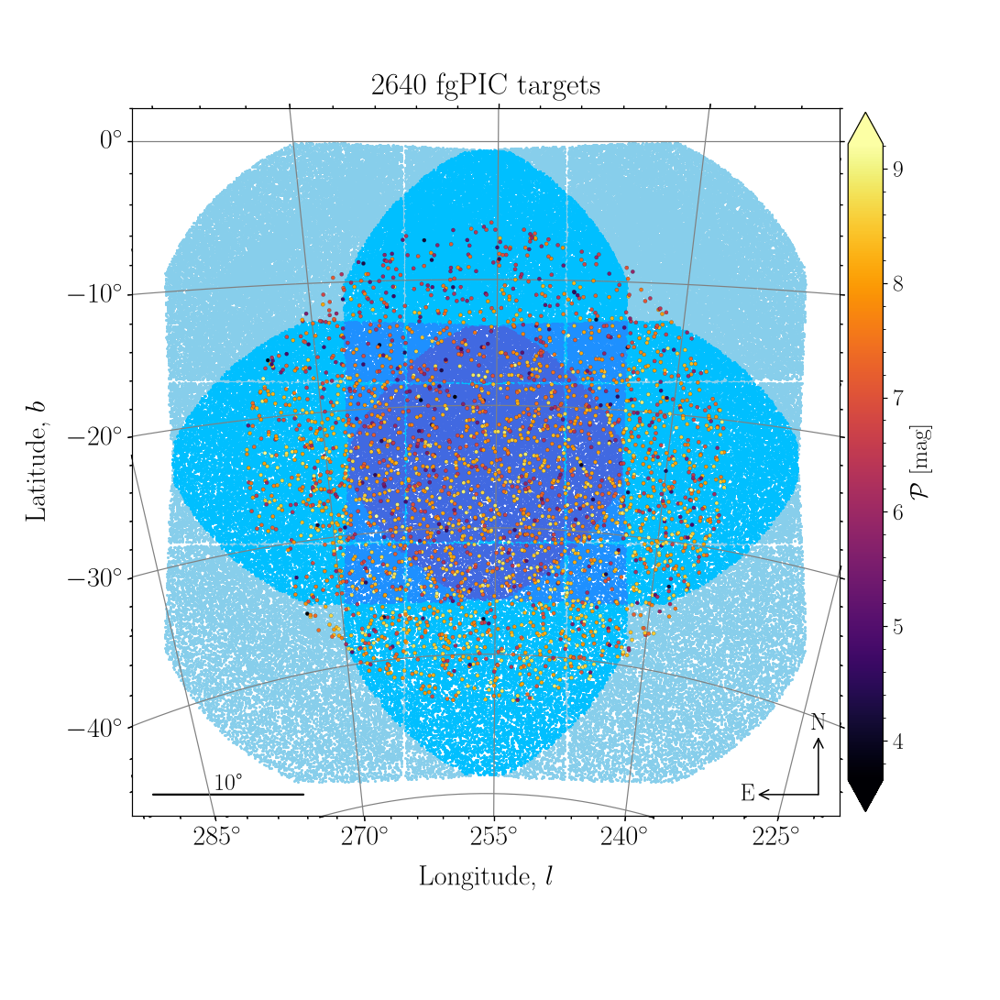

In [241]:
dx = dt.loc[(dt.source & 8 == 8)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} fgPIC targets'
)

Plot fgPIC `F-CAMb` targets:

<IPython.core.display.Javascript object>


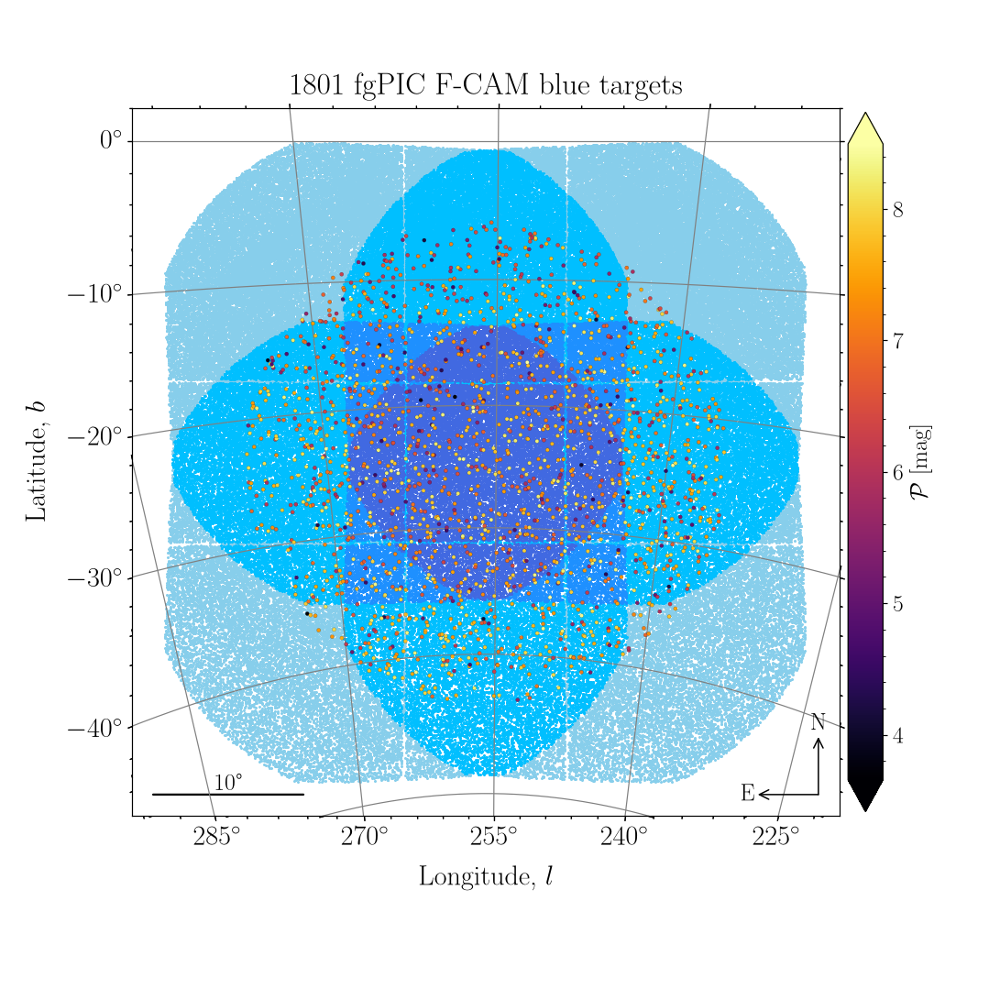

In [242]:
dx = dt.loc[(dt.fgPIC & 1 == 1)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} fgPIC F-CAM blue targets'
)

Plot fgPIC `F-CAMr` targets:

<IPython.core.display.Javascript object>


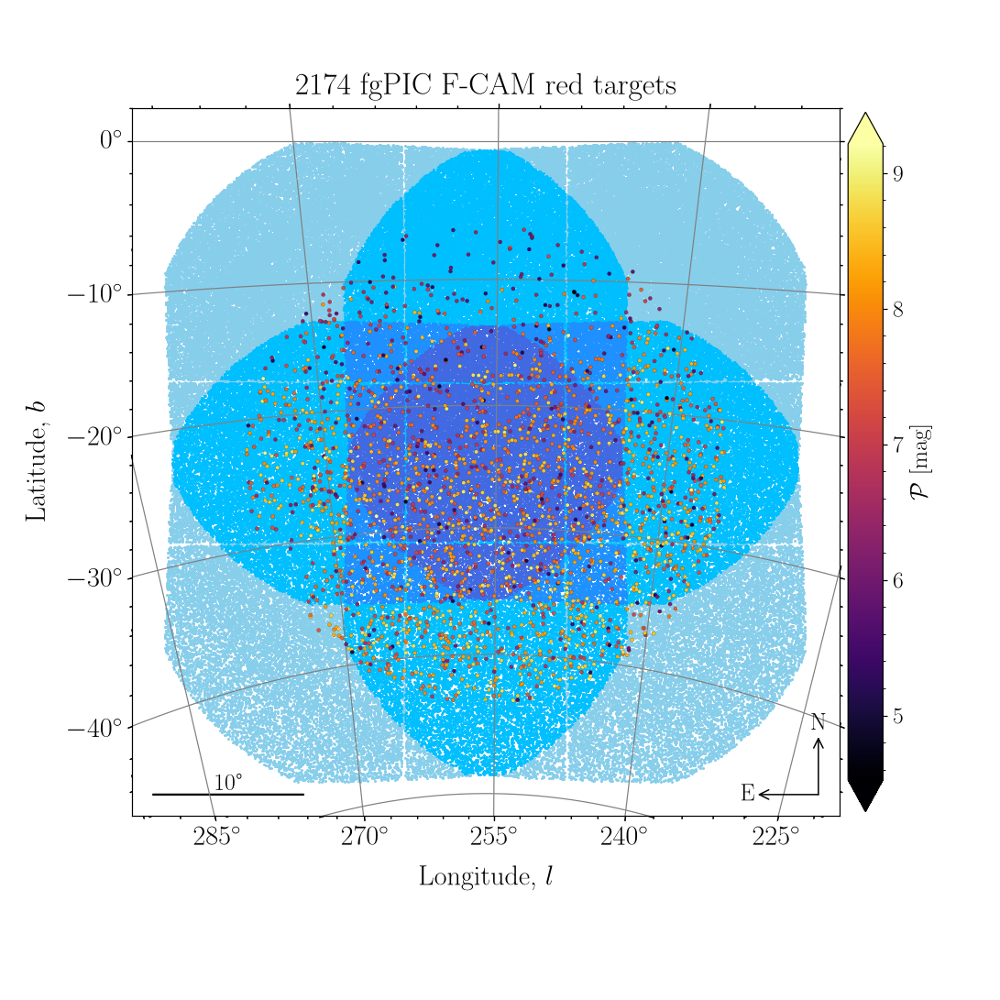

In [243]:
dx = dt.loc[(dt.fgPIC & 2 == 2)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} fgPIC F-CAM red targets'
)

---
### Plots for cPIC

Plot `cPIC` targets:

<IPython.core.display.Javascript object>


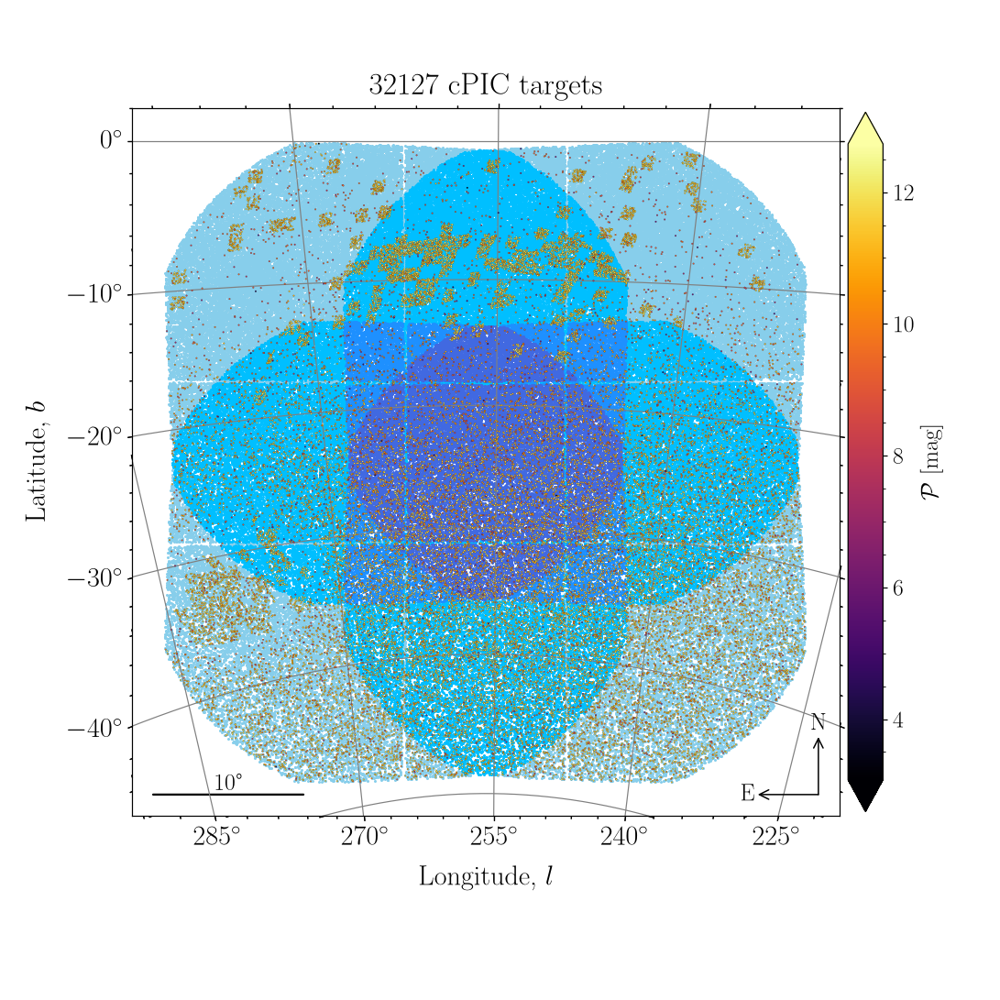

In [245]:
dx = dt[(dt.source & 16 == 16) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} cPIC targets'
)

Plot cPIC `F-CAM R1` sample:

<IPython.core.display.Javascript object>


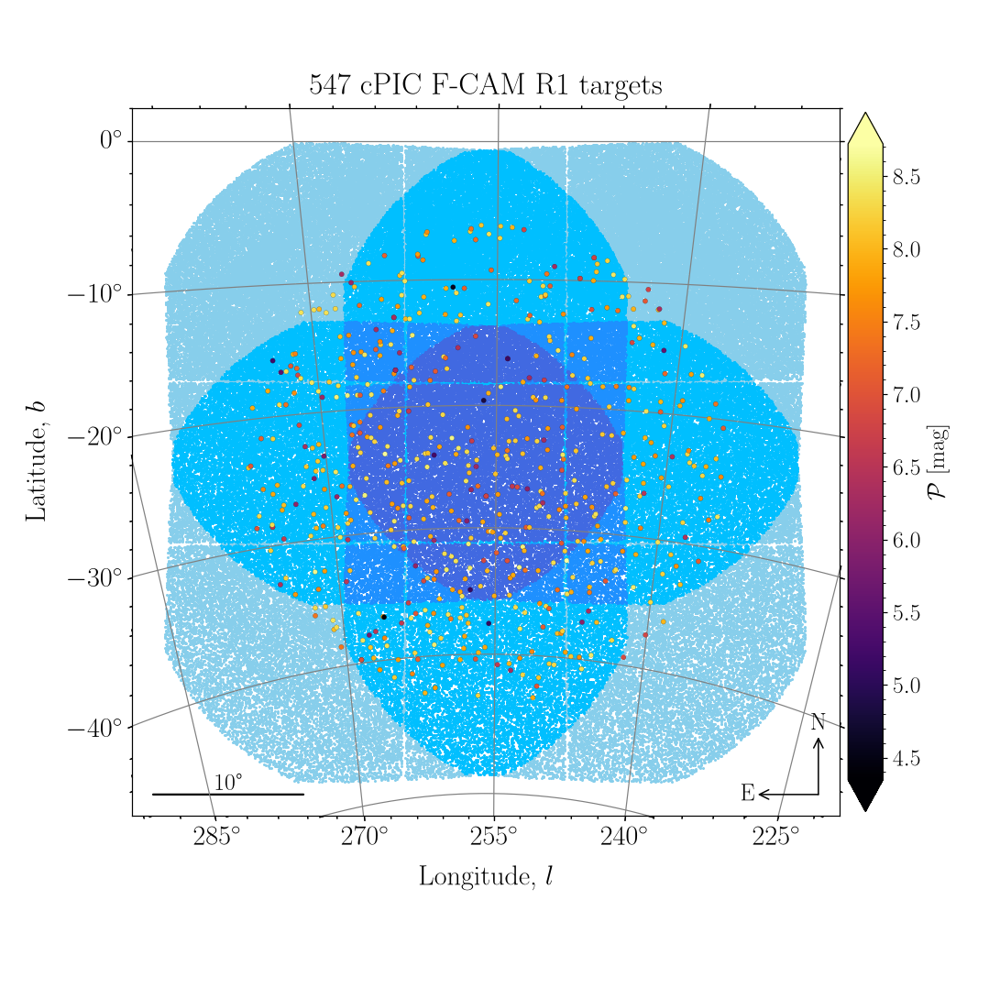

In [246]:
dx = dt[(dt.cPIC & 1 == 1)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} cPIC F-CAM R1 targets'
)

Plot cPIC `F-CAM R2` sample:

<IPython.core.display.Javascript object>


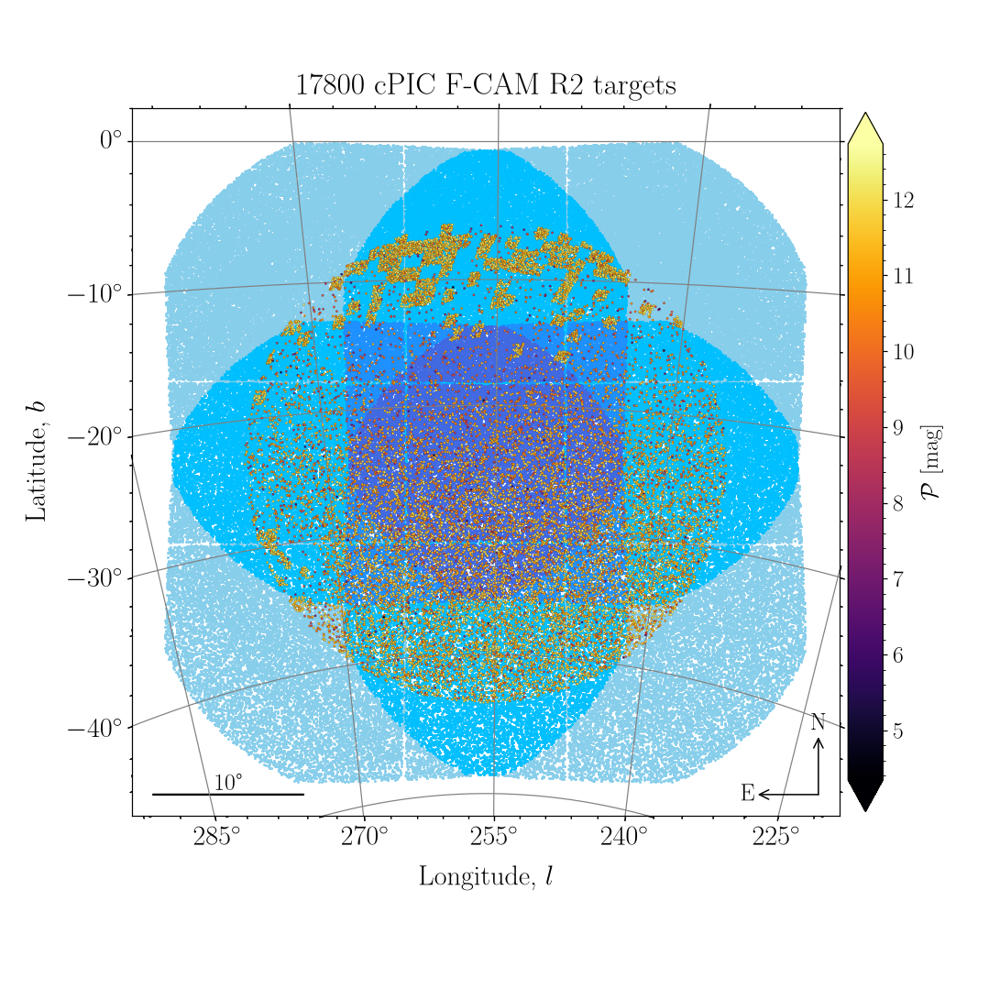

In [247]:
dx = dt[(dt.cPIC & 2 == 2)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} cPIC F-CAM R2 targets'
)

Plot cPIC `F-CAM R3` sample:

<IPython.core.display.Javascript object>


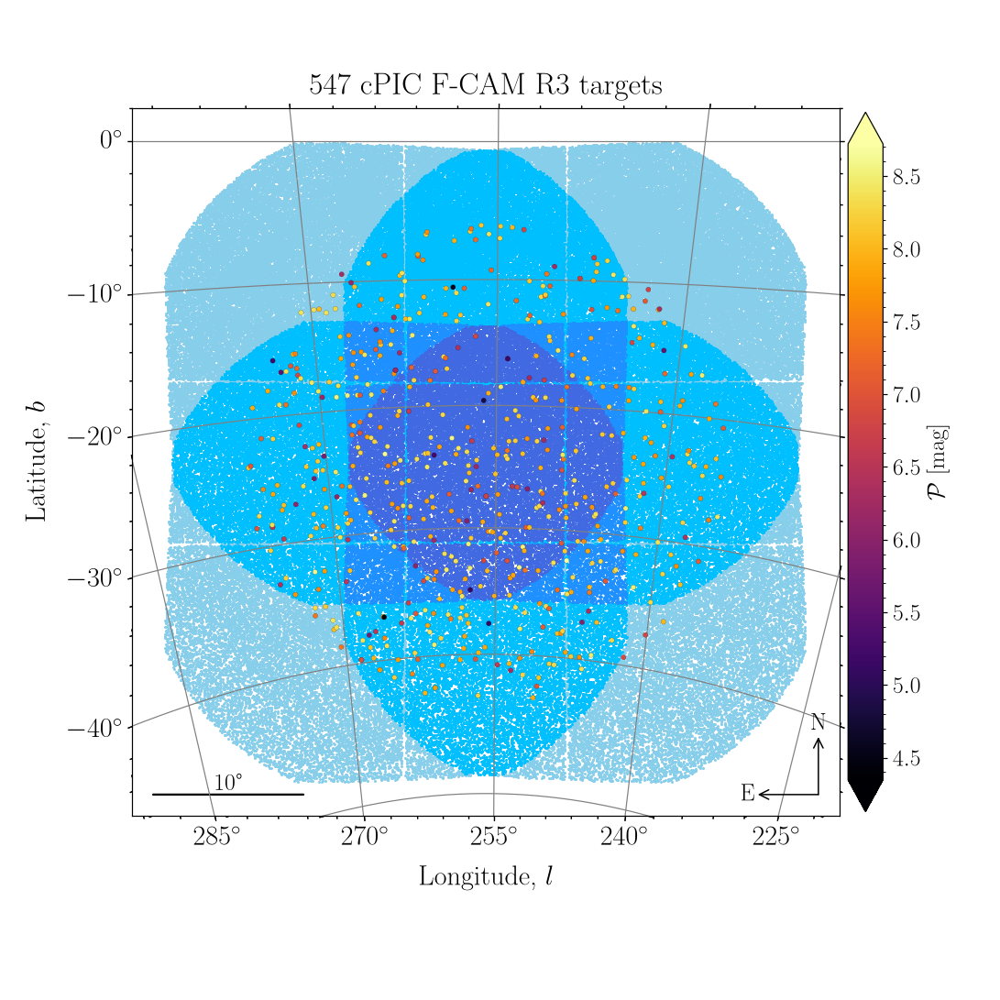

In [248]:
dx = dt[(dt.cPIC & 4 == 4)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} cPIC F-CAM R3 targets'
)

Plot `cPIC F-CAM R4` sample:

<IPython.core.display.Javascript object>


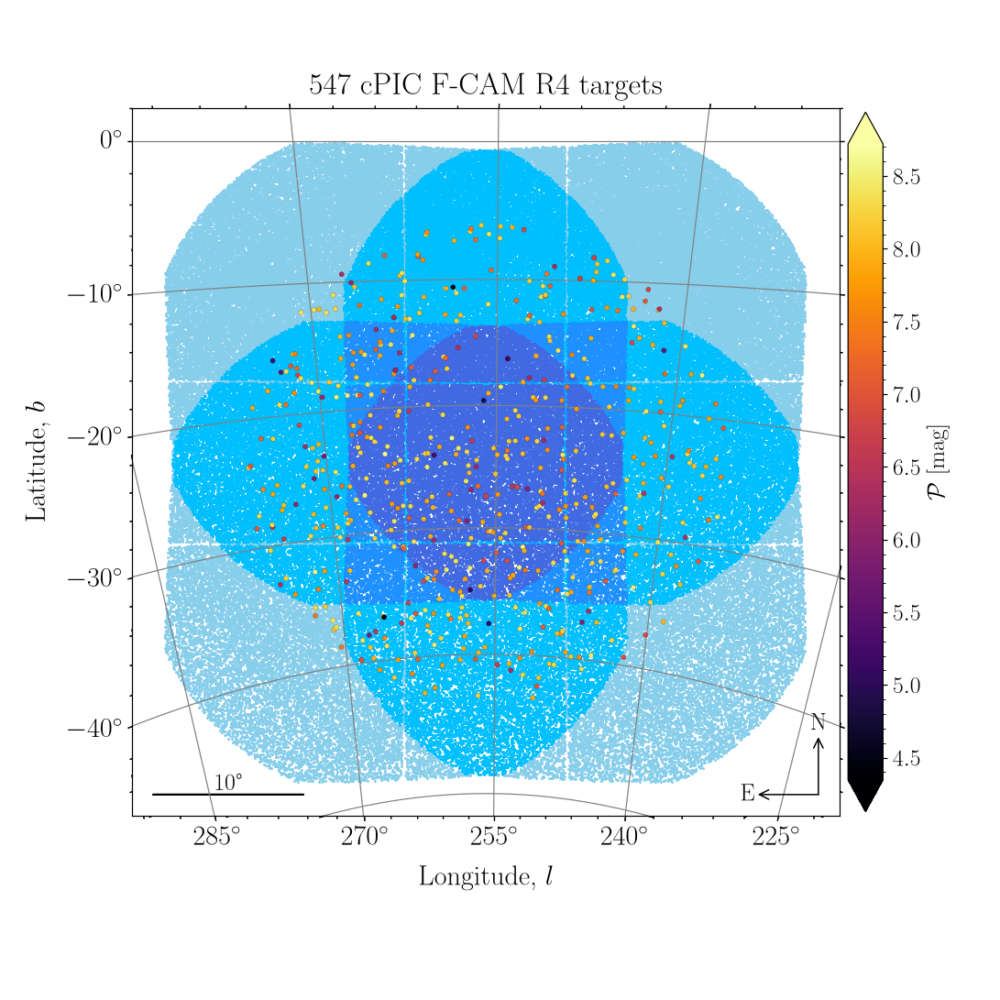

In [249]:
dx = dt[(dt.cPIC & 8 == 8)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} cPIC F-CAM R4 targets'
)

Plot cPIC `F-CAM R5` sample:

<IPython.core.display.Javascript object>


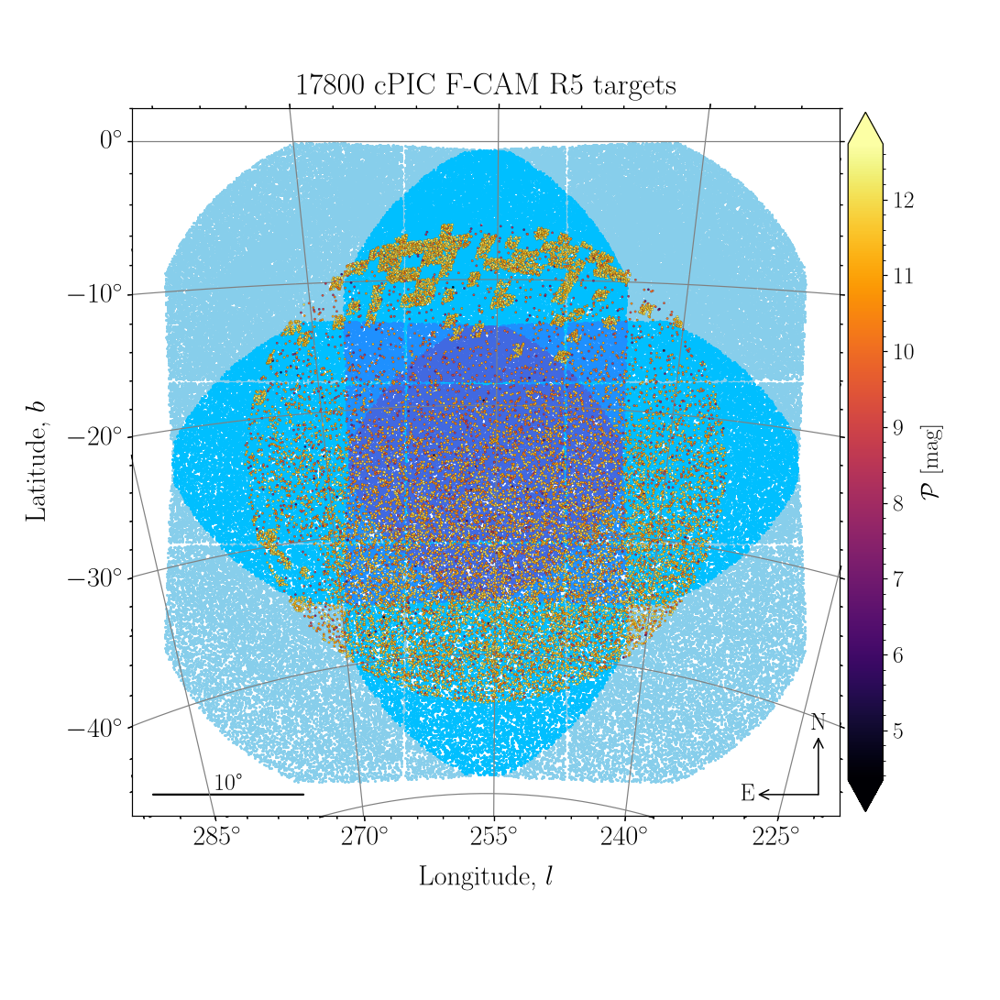

In [250]:
dx = dt[(dt.cPIC & 16 == 16)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} cPIC F-CAM R5 targets'
)

Plot cPIC `N-CAM R1` sample:

<IPython.core.display.Javascript object>


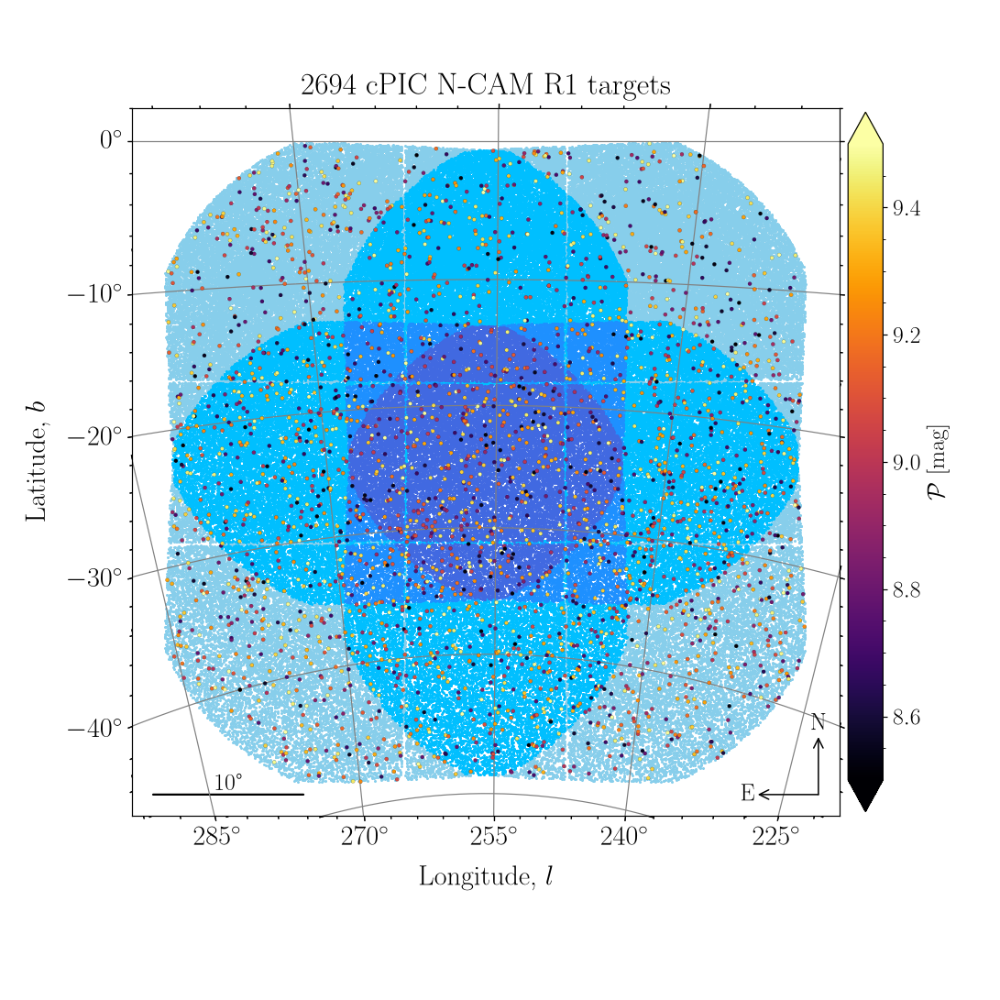

In [251]:
dx = dt[(dt.cPIC & 32 == 32) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} cPIC N-CAM R1 targets'
)

Plot cPIC `N-CAM R2` sample:

<IPython.core.display.Javascript object>


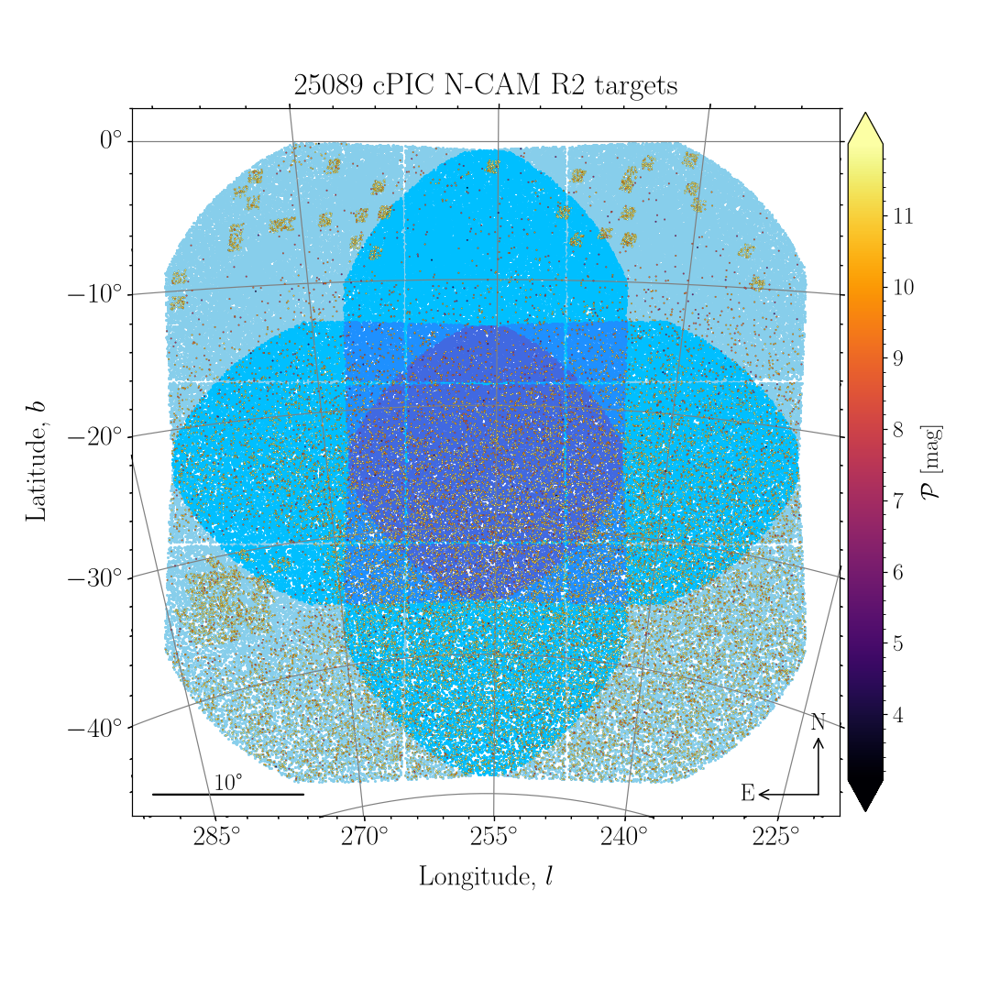

In [252]:
dx = dt[(dt.cPIC & 64 == 64) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} cPIC N-CAM R2 targets'
)

Plot cPIC `N-CAM R3` sample:

<IPython.core.display.Javascript object>


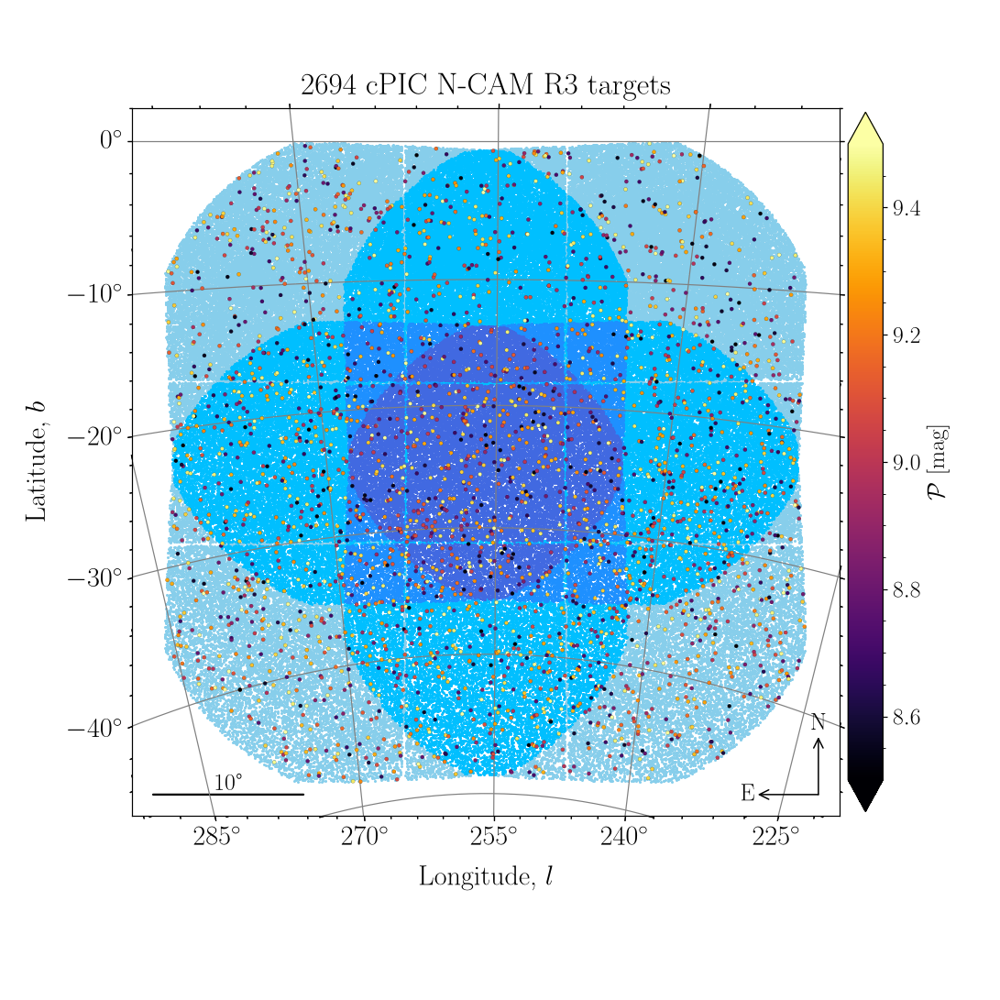

In [253]:
dx = dt[(dt.cPIC & 128 == 128) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} cPIC N-CAM R3 targets'
)

Plot cPIC `N-CAM R4` sample:

<IPython.core.display.Javascript object>


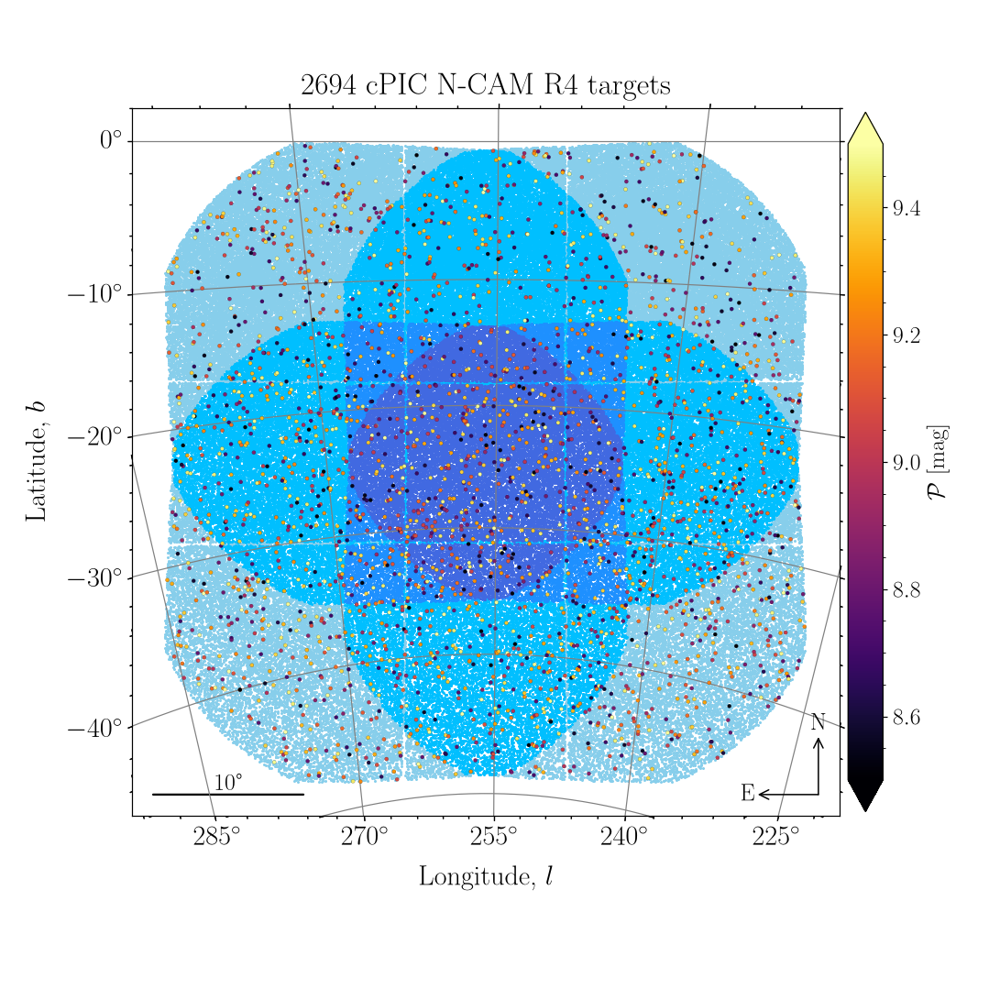

In [254]:
dx = dt[(dt.cPIC & 256 == 256) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} cPIC N-CAM R4 targets'
)

Plot cPIC `N-CAM R5` sample:

<IPython.core.display.Javascript object>


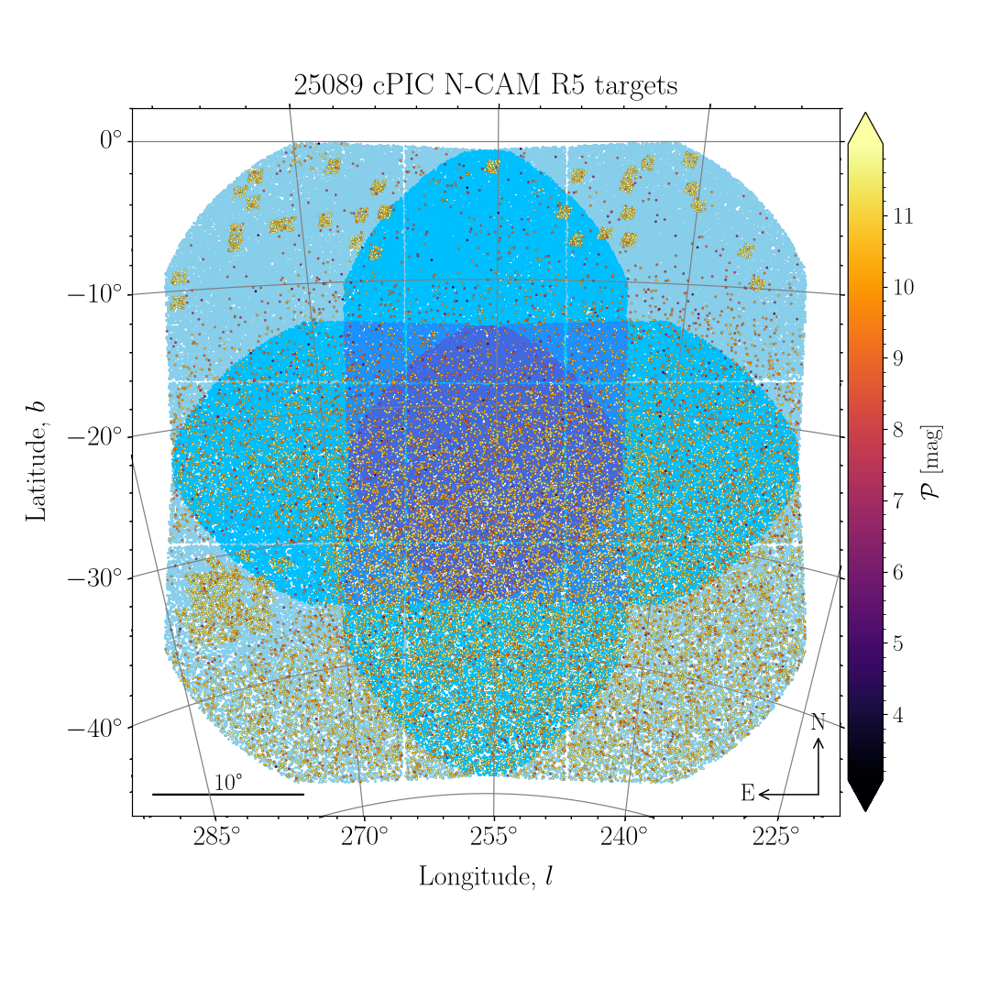

In [257]:
dx = dt[(dt.cPIC & 512 == 512) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} cPIC N-CAM R5 targets'
)

---
### Plots for scvPIC

Plot `scvPIC` targets:

<IPython.core.display.Javascript object>


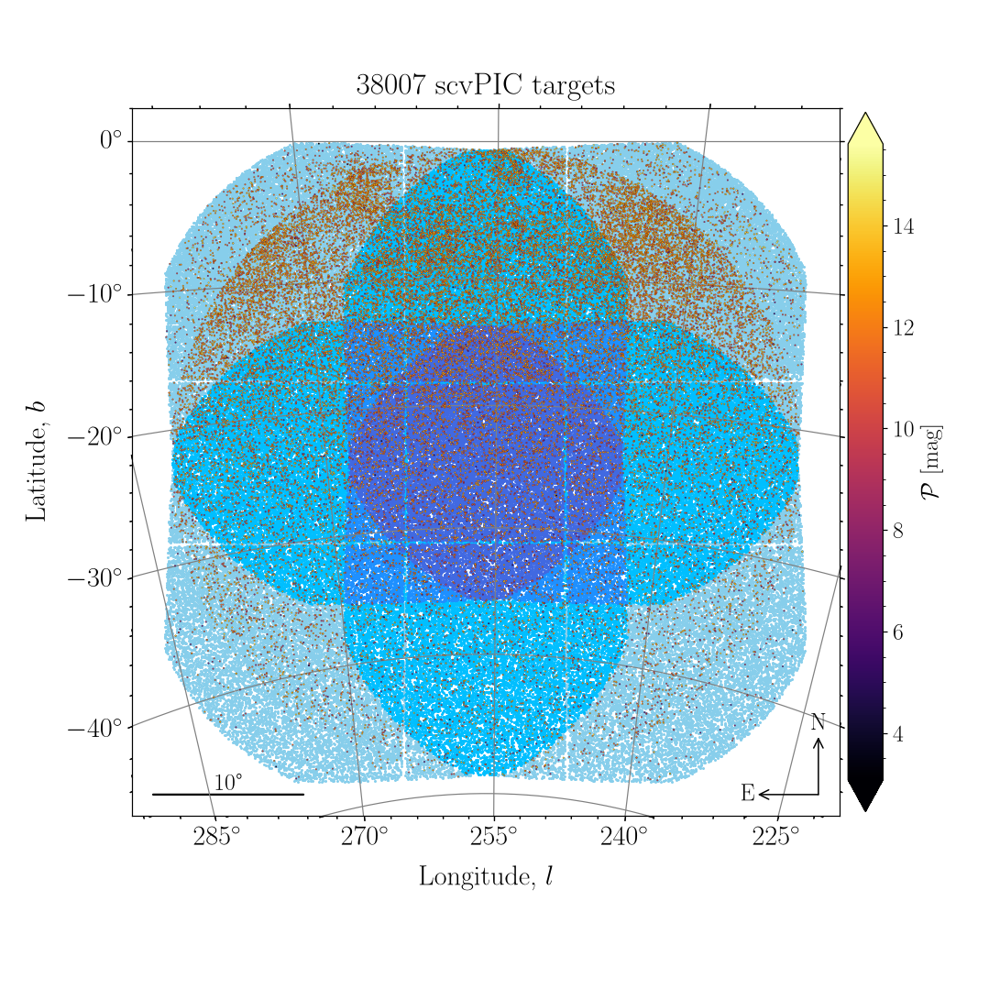

In [258]:
dx = dt[(dt.source & 32 == 32) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} scvPIC targets'
)

Plot scvPIC `SCV1a` sample (eclipsing binaries):

<IPython.core.display.Javascript object>


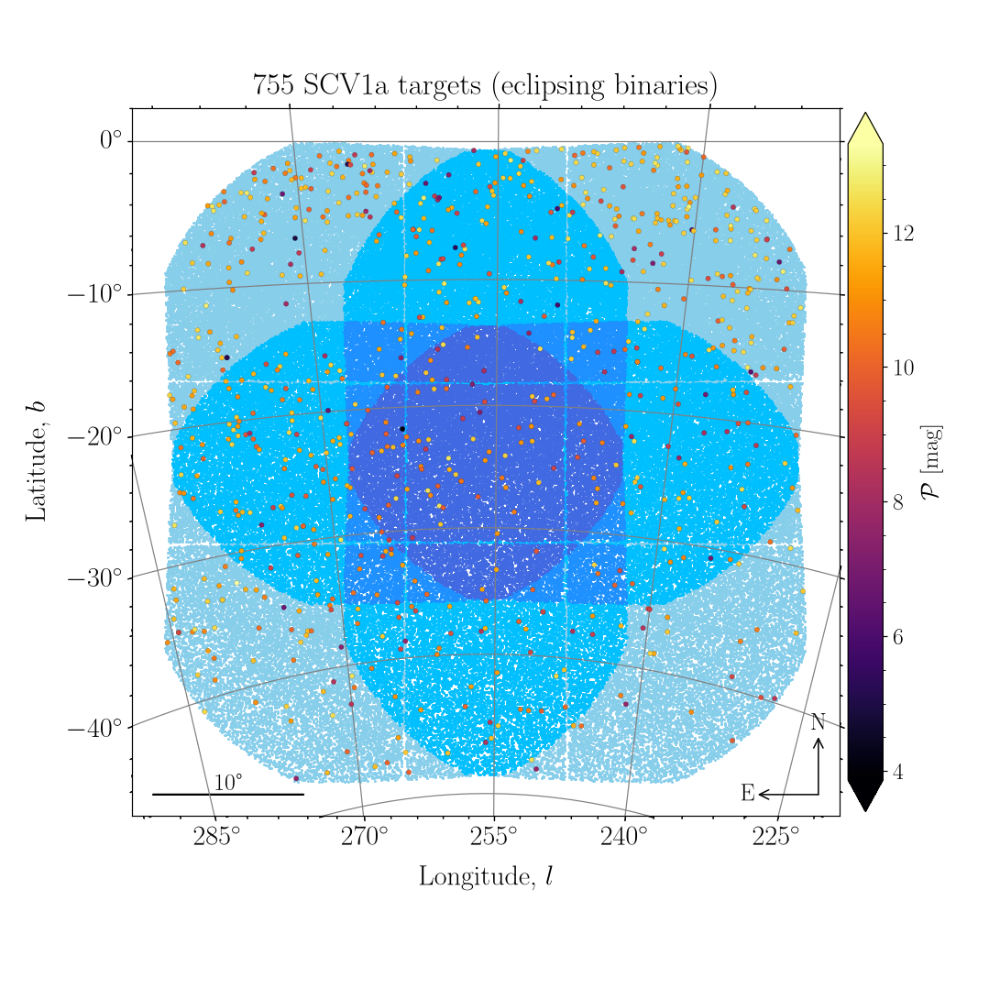

In [259]:
dx = dt[(dt.scvPIC & 1 == 1) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} SCV1a targets (eclipsing binaries)'
)

Plot scvPIC `SCV1b` sample (astrometric binaries):

<IPython.core.display.Javascript object>


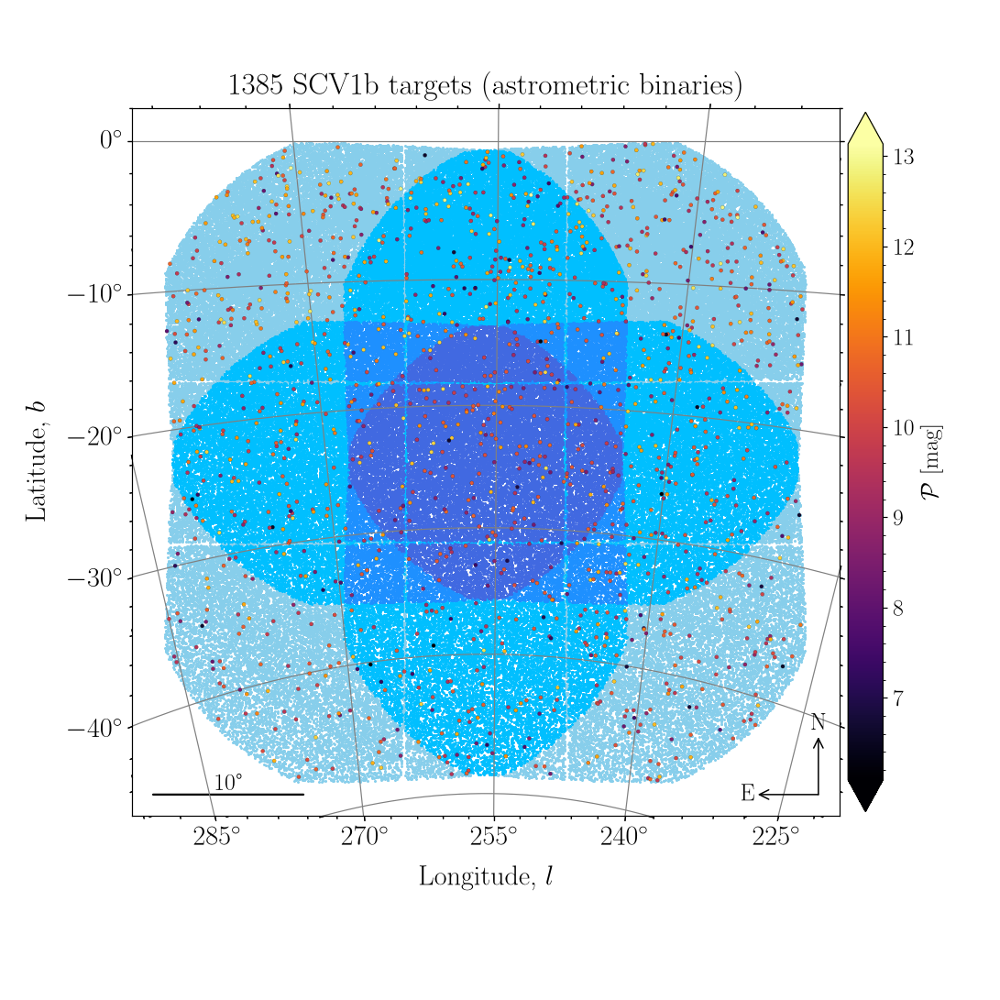

In [260]:
dx = dt[(dt.scvPIC & 2 == 2) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} SCV1b targets (astrometric binaries)'
)

Plot scvPIC `SCV1c` sample (wide binaries):

<IPython.core.display.Javascript object>


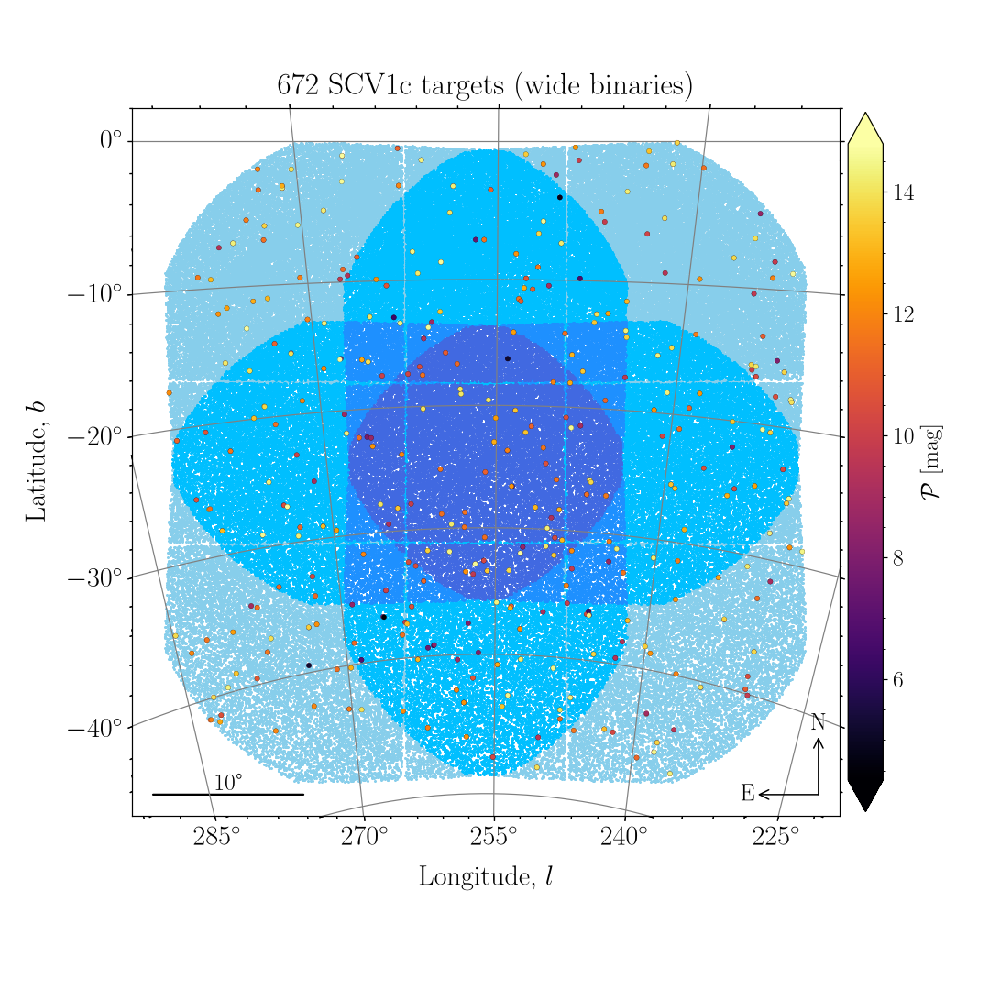

In [262]:
dx = dt[(dt.scvPIC & 4 == 4) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} SCV1c targets (wide binaries)'
)

Plot scvPIC `SCV1d` sample (HW Vir-type binaries):

<IPython.core.display.Javascript object>


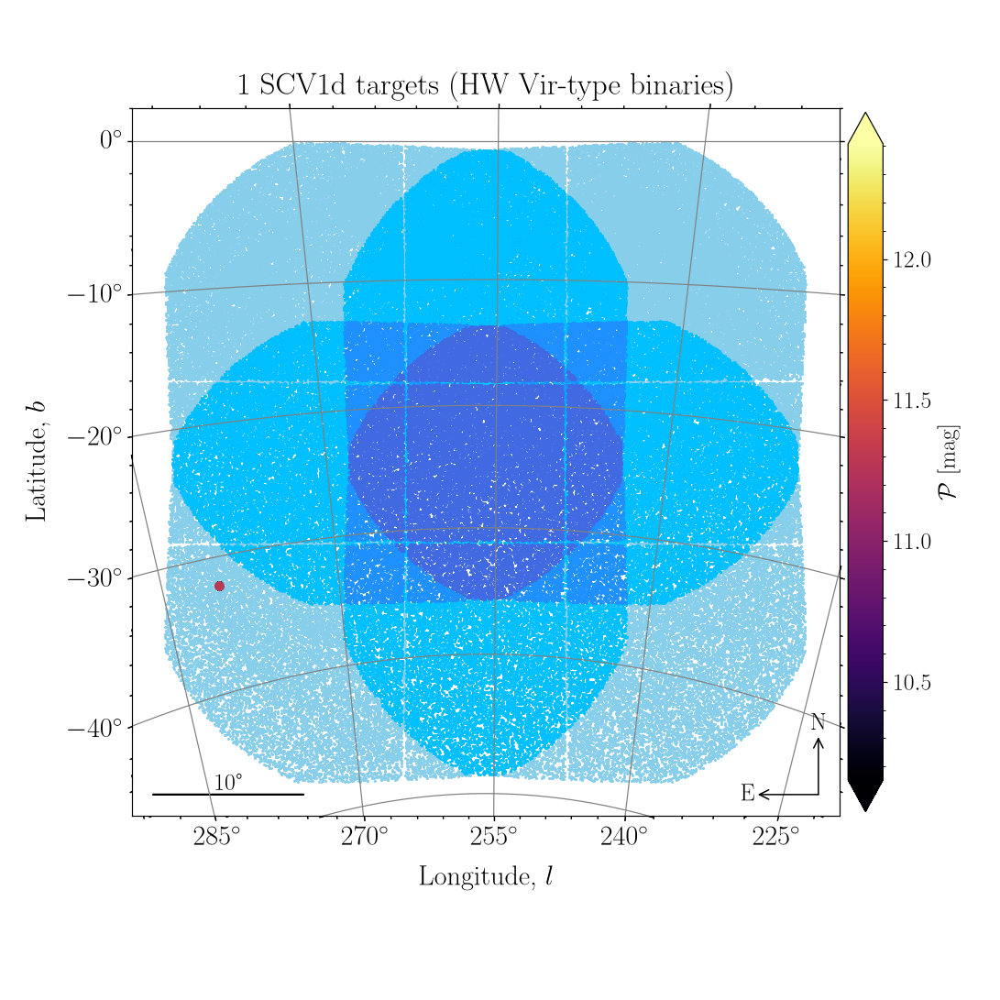

In [263]:
dx = dt[(dt.scvPIC & 8 == 8) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} SCV1d targets (HW Vir-type binaries)'
)

Plot scvPIC `SCV1e` sample (wide WD binaries):

<IPython.core.display.Javascript object>


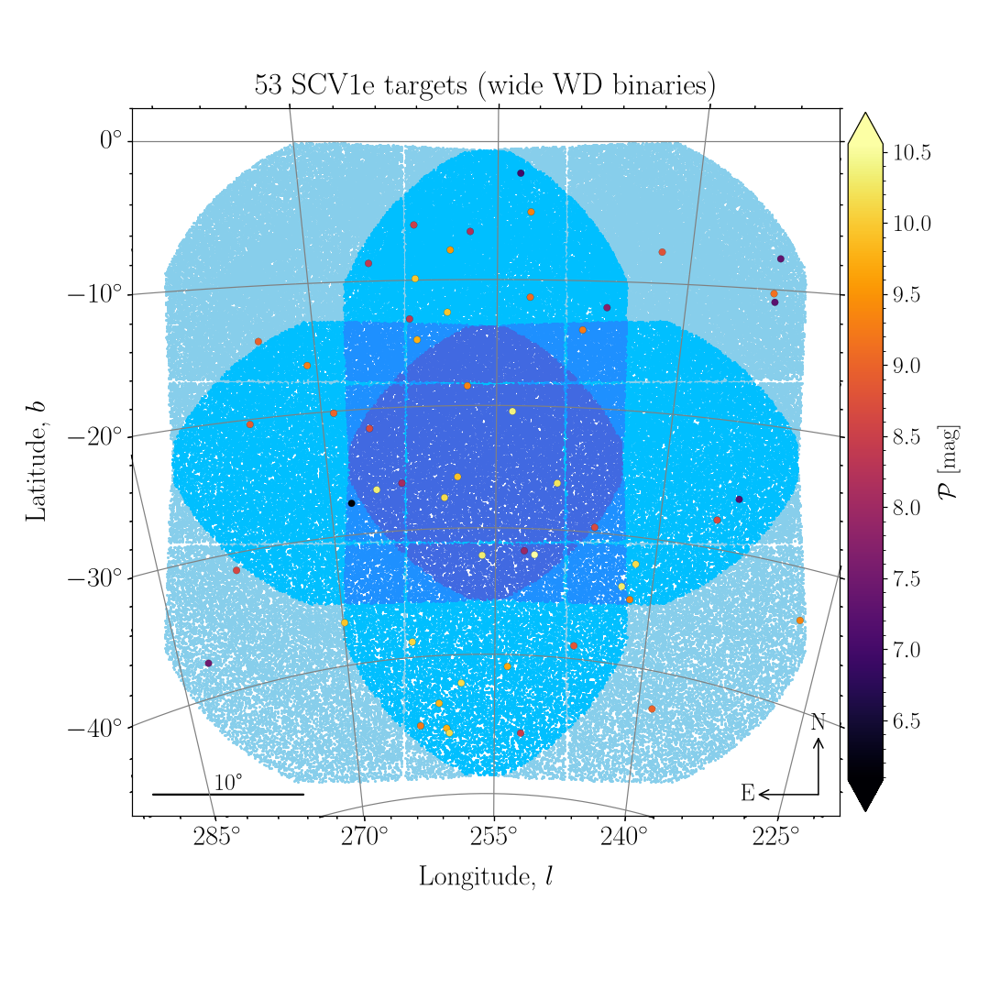

In [264]:
dx = dt[(dt.scvPIC & 16 == 16) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} SCV1e targets (wide WD binaries)'
)

Plot scvPIC `SCV2a` sample (legacy and benchmark):

<IPython.core.display.Javascript object>


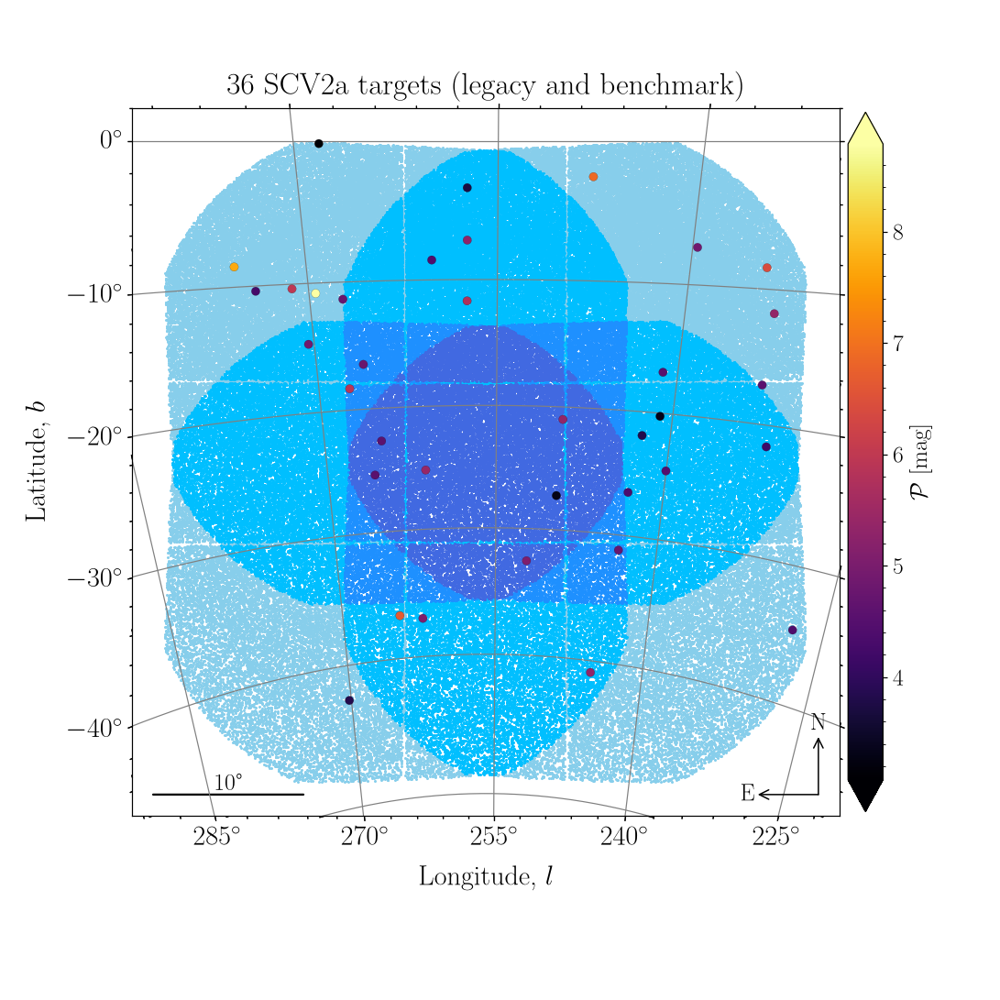

In [266]:
dx = dt[(dt.scvPIC & 32 == 32) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} SCV2a targets (legacy and benchmark)'
)

Plot scvPIC `SCV2b` sample (legacy and benchmark):

<IPython.core.display.Javascript object>


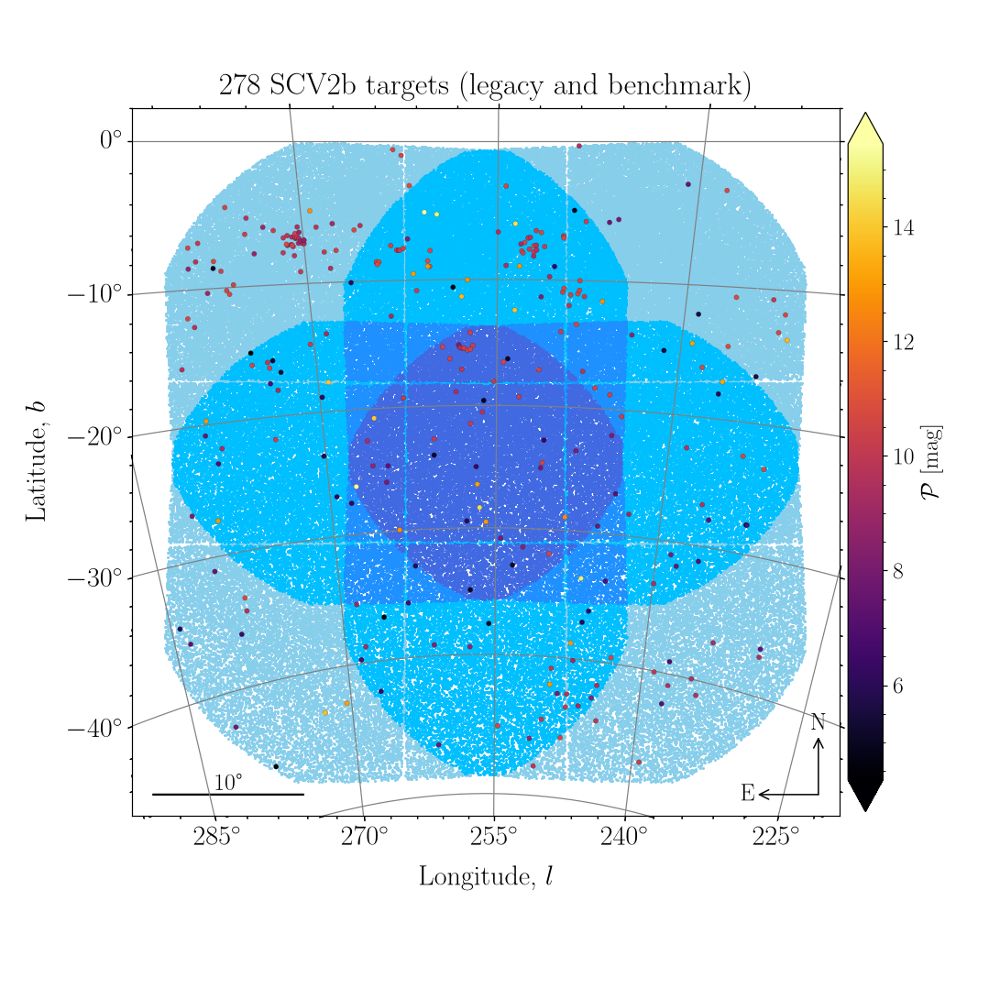

In [268]:
dx = dt[(dt.scvPIC & 64 == 64) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} SCV2b targets (legacy and benchmark)'
)

Plot scvPIC `SCV3a` sample (photometric stable):

<IPython.core.display.Javascript object>


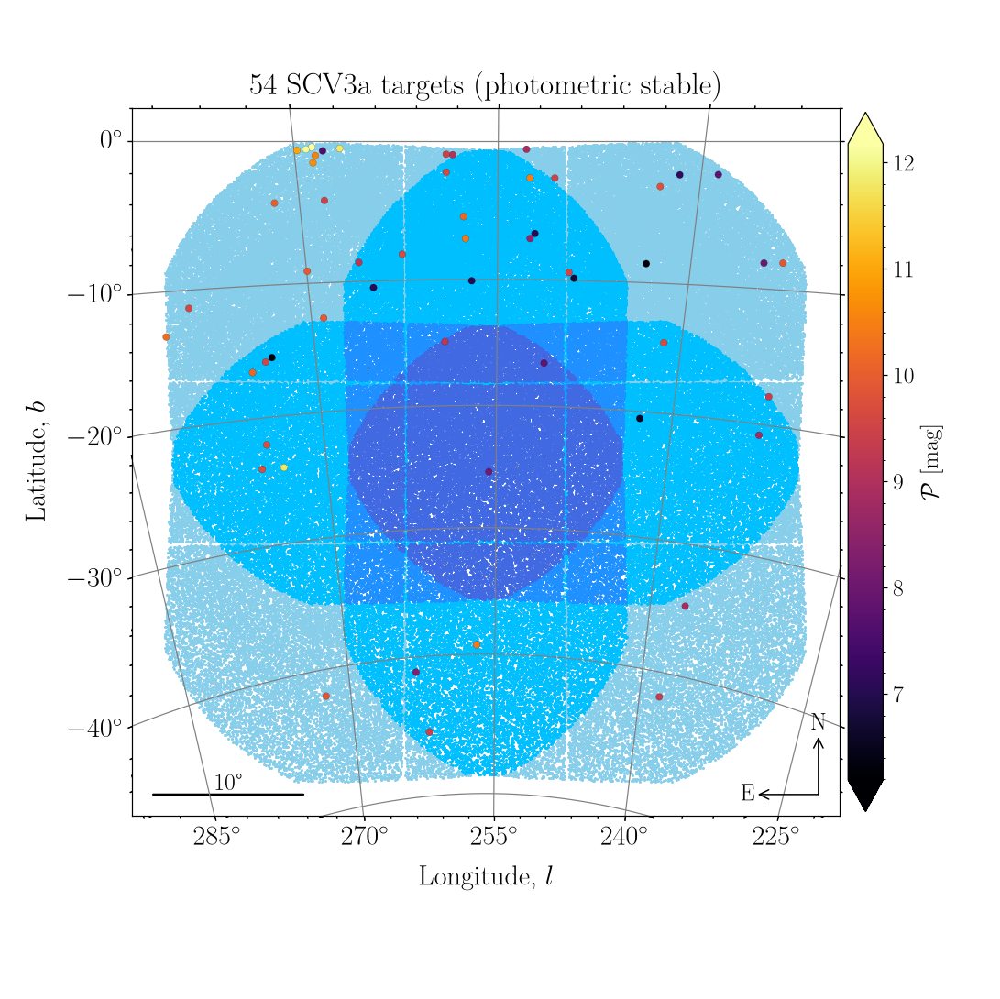

In [269]:
dx = dt[(dt.scvPIC & 128 == 128) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} SCV3a targets (photometric stable)'
)

Plot scvPIC `SCV3b` sample (photometric stable):

<IPython.core.display.Javascript object>


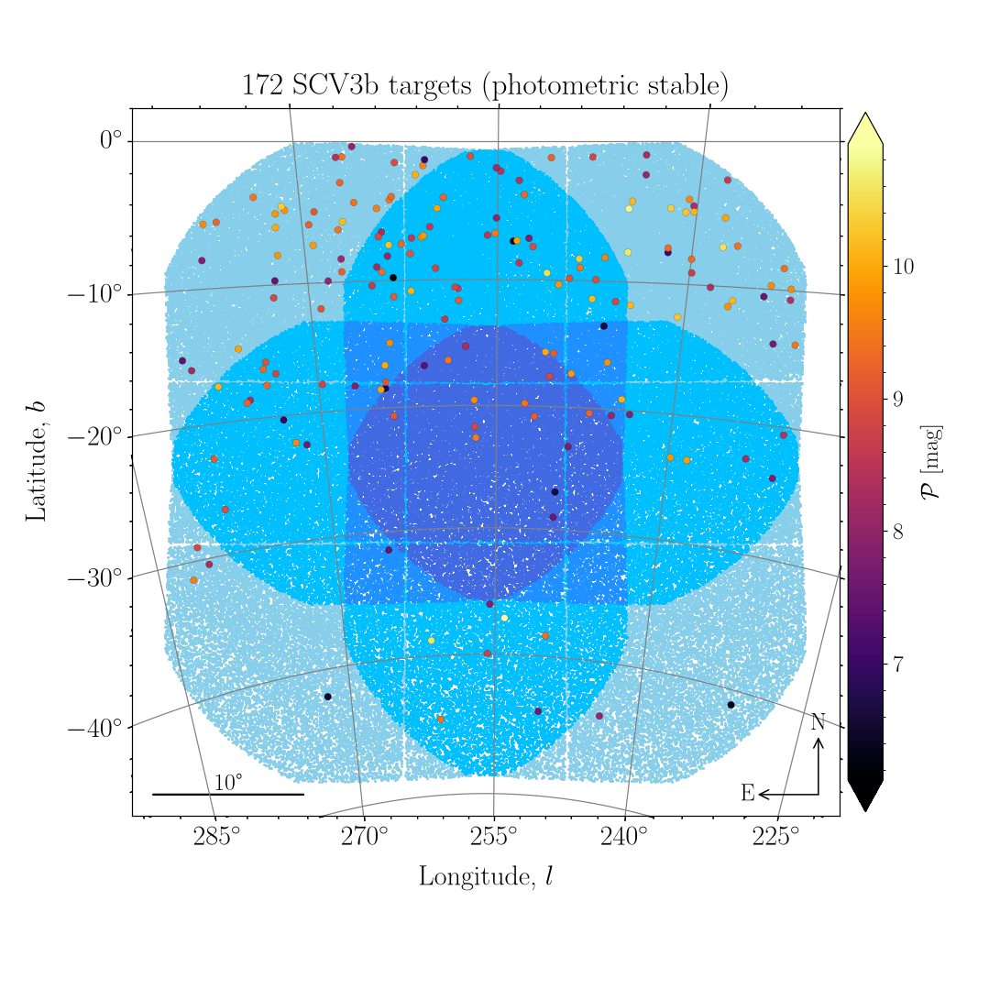

In [270]:
dx = dt[(dt.scvPIC & 256 == 256) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} SCV3b targets (photometric stable)'
)

Plot scvPIC `SCV4a` sample (solar-like pulsators):

<IPython.core.display.Javascript object>


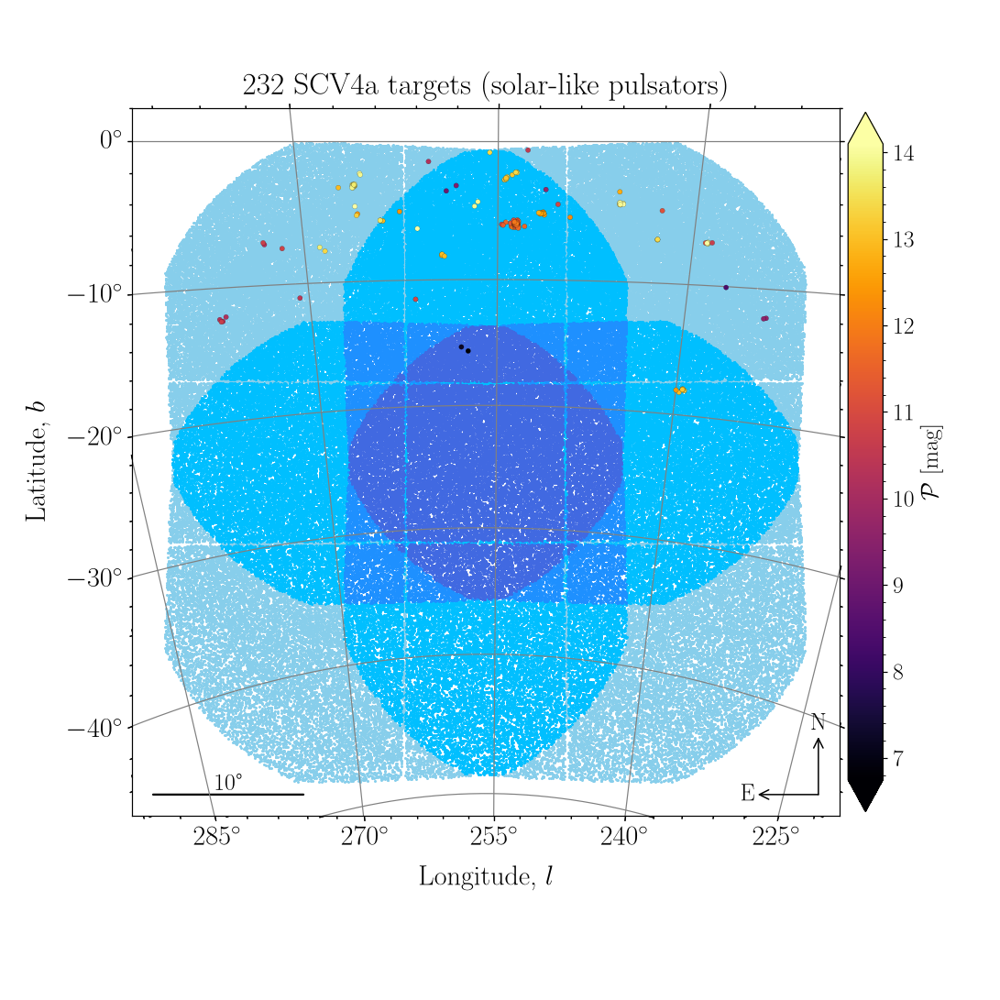

In [271]:
dx = dt[(dt.scvPIC & 512 == 512) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} SCV4a targets (solar-like pulsators)'
)

Plot scvPIC `SCV4b` sample (solar-like pulsators):

<IPython.core.display.Javascript object>


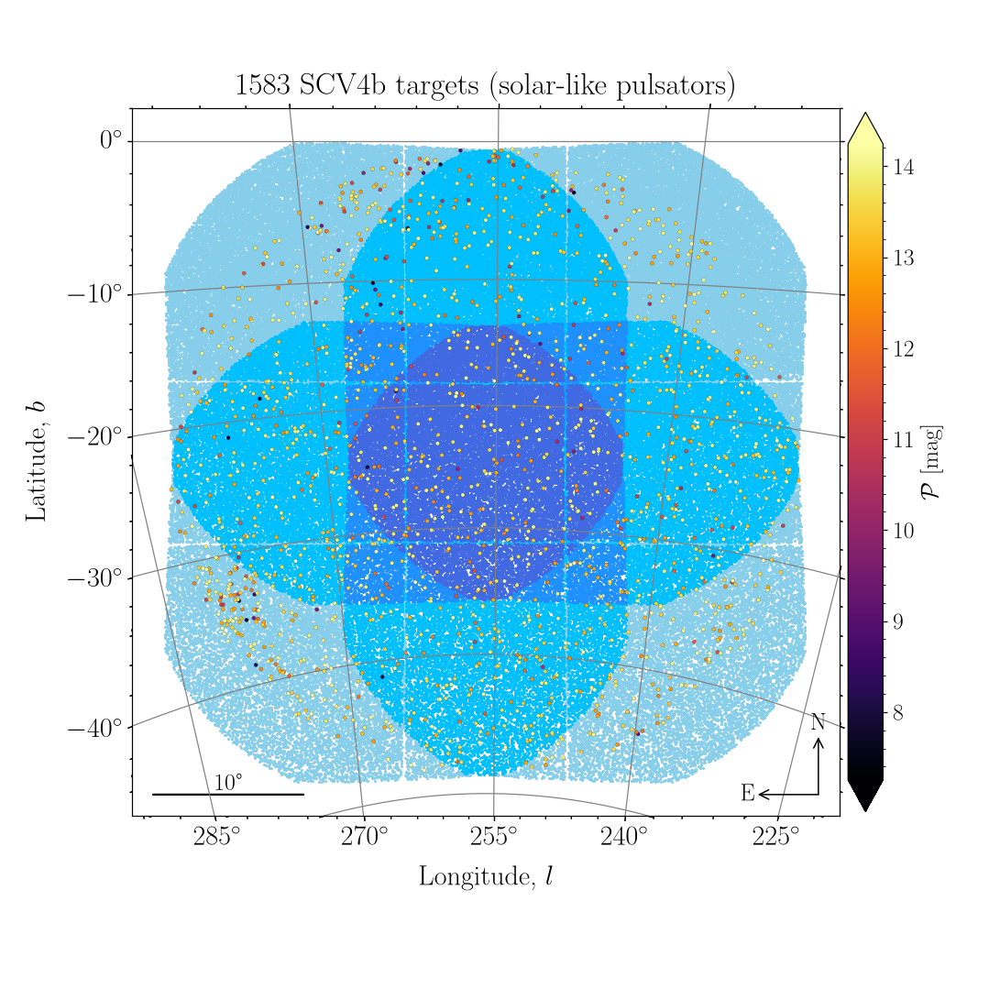

In [272]:
dx = dt[(dt.scvPIC & 1024 == 1024) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} SCV4b targets (solar-like pulsators)'
)

Plot scvPIC `SCV5` sample (gamma Dor pulsators):

<IPython.core.display.Javascript object>


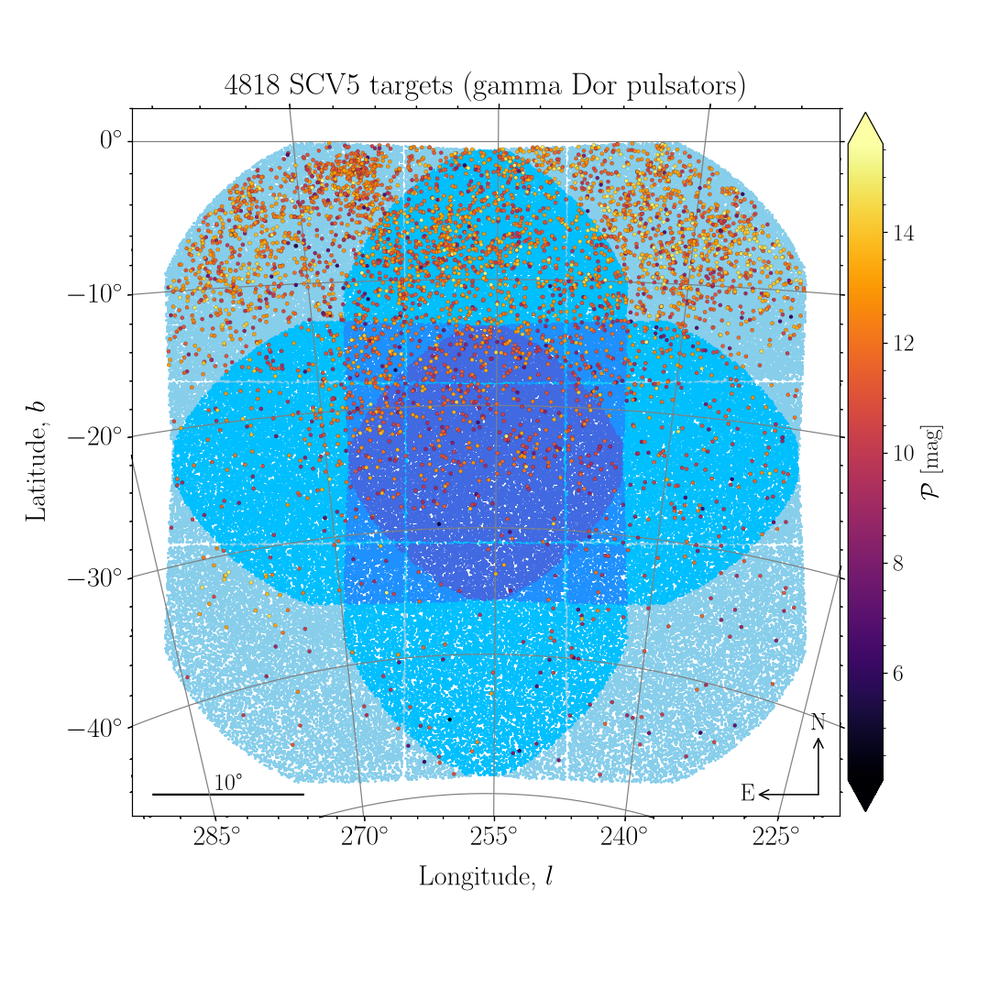

In [273]:
dx = dt[(dt.scvPIC & 2048 == 2048) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} SCV5 targets (gamma Dor pulsators)'
)

Plot scvPIC `SCV6` sample (transiting exoplanets):

<IPython.core.display.Javascript object>


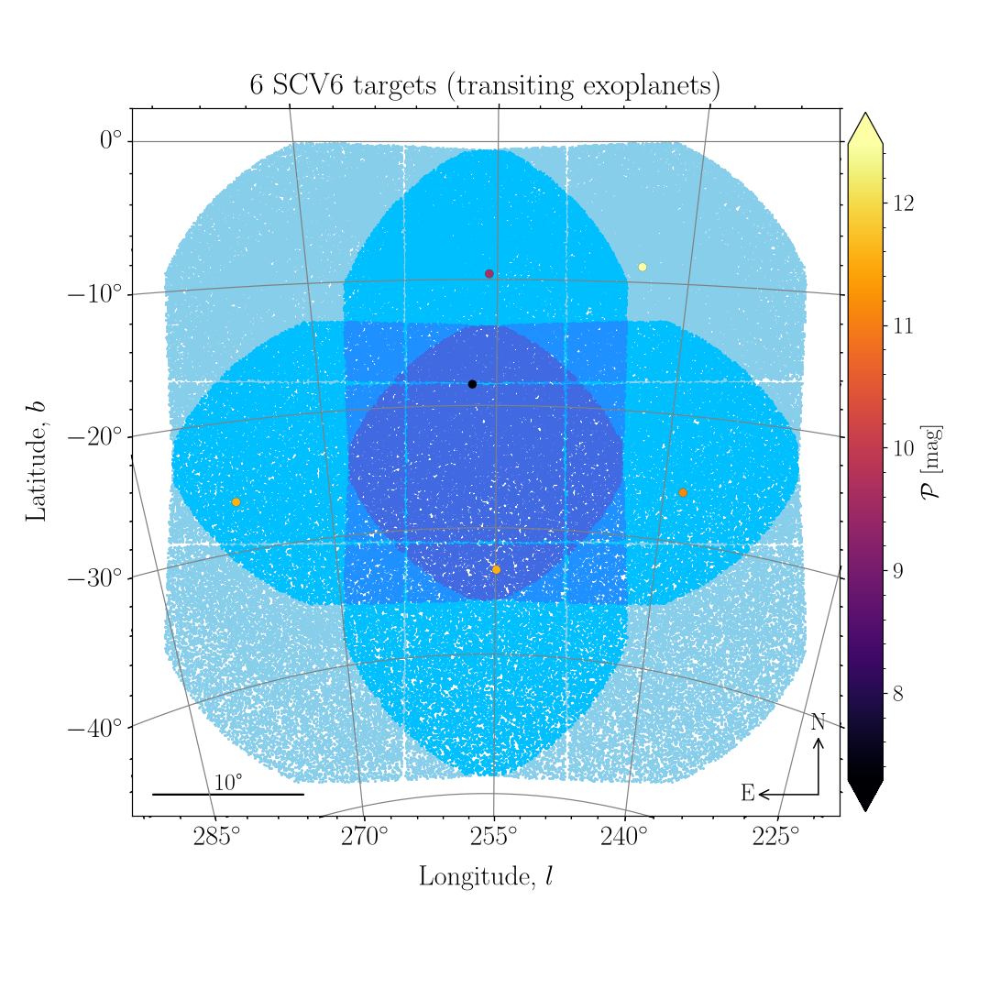

In [278]:
dx = dt[(dt.scvPIC & 4096 == 4096) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=dt0,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    figsize=(10,10), title=f'{dx.shape[0]} SCV6 targets (transiting exoplanets)'
)